In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('sales_transactions_raw.csv')
df

,order_id,order_date,region,channel,customer_id,customer_type,sales_rep,category,product,qty,discount,status,unit_price,revenue,cost
0,ORD-100001,2024-09-01,Jakarta,Offline,C00438,UMKM,SR02,Smartphone,Smartphone Lumo X,4,0.10,Completed,5500000.0,19800000.0,19274000.0
1,ORD-100002,2024-09-01,Jawa Timur,Offline,K0002,Korporat,SR09,Peralatan Kantor,Kursi Ergonomis E1,20,0.10,Completed,1900000.0,34200000.0,26338000.0
2,ORD-100003,2024-09-01,Jawa Barat,Online,C01918,Retail,SYS-ONLINE,Laptop,Laptop Axio Pro 15,1,0.10,Completed,13000000.0,11700000.0,11642500.0
3,ORD-100004,2024-09-01,Kalimantan,Offline,C00108,Retail,SR14,Aksesoris,Keyboard Mekanik K7,1,0.00,Completed,650000.0,650000.0,401000.0
4,ORD-100005,2024-09-01,Sulawesi,Online,C01567,Retail,SYS-ONLINE,Smartphone,Smartphone Lumo X,2,0.10,Completed,5500000.0,9900000.0,9743000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7304,ORD-106316,2026-07-12,Jakarta,Online,C01917,UMKM,SYS-ONLINE,Smartphone,Smartphone Lumo A5,5,0.30,Completed,2800000.0,9800000.0,12172000.0
7305,ORD-106616,2026-08-12,Jakarta,Online,C01901,Retail,SYS-ONLINE,Peralatan Kantor,Kursi Ergonomis E1,3,0.20,Completed,1900000.0,4560000.0,3873000.0
7306,ORD-106617,2026-08-12,Sumatra,Online,C00127,Retail,SYS-ONLINE,Printer & Tinta,Tinta Botol Set CMYK,2,0.30,Completed,280000.0,392000.0,334800.0
7307,ORD-106620,2026-08-12,Sumatera,Online,C00413,Retail,SYS-ONLINE,Smartphone,Smartphone Lumo A5,1,0.15,Completed,2800000.0,2380000.0,2448600.0


In [3]:
# Statistical Summary
df.describe()

,qty,discount,unit_price,revenue,cost
count,7309.000000,7309.000000,7.309000e+03,7.309000e+03,6.789000e+03
mean,5.385278,0.428825,2.474544e+06,7.443051e+06,6.726647e+06
std,14.765838,2.339969,3.464762e+06,2.680444e+07,2.497317e+07
min,-219.000000,0.000000,0.000000e+00,-4.950000e+07,-4.341420e+07
25%,1.000000,0.000000,1.800000e+05,3.600000e+05,2.114000e+05
50%,3.000000,0.050000,6.500000e+05,2.380000e+06,1.711200e+06
75%,5.000000,0.100000,2.800000e+06,8.400000e+06,7.569100e+06
max,400.000000,30.000000,1.300000e+07,1.700000e+09,1.517220e+09


In [4]:
# Data Types
df.dtypes

order_id             str
order_date           str
region               str
channel              str
customer_id          str
customer_type        str
sales_rep            str
category             str
product              str
qty                int64
discount         float64
status               str
unit_price       float64
revenue          float64
cost             float64
dtype: object

In [5]:
# Cek data dari tanggal berapa sampai tanggal berapa
df['order_date'].min(), df['order_date'].max()

('01/04/2026', '31/08/2026')

## QUALITY CHECK

In [6]:
# Cek missing values
df.isnull().sum()

order_id           0
order_date         0
region           134
channel            0
customer_id        0
customer_type      0
sales_rep          0
category           0
product            0
qty                0
discount           0
status             0
unit_price         0
revenue            0
cost             520
dtype: int64

In [7]:
# Cek duplikasi data
df.duplicated().sum()

np.int64(150)

In [8]:
# Cek number of unique values in each column
df.nunique()

order_id         7159
order_date        908
region             16
channel             5
customer_id      2392
customer_type       3
sales_rep          20
category           16
product            15
qty                97
discount           14
status              3
unit_price         32
revenue          1273
cost             5413
dtype: int64

In [9]:
# Unique Values in each column
for column in df.columns:
    print(f"Unique values in column '{column}':")
    print(df[column].unique())
    print()

Unique values in column 'order_id':
<ArrowStringArray>
['ORD-100001', 'ORD-100002', 'ORD-100003', 'ORD-100004', 'ORD-100005',
 'ORD-100006', 'ORD-100007', 'ORD-100008', 'ORD-100009', 'ORD-100010',
 ...
 'ORD-105999', 'ORD-106308', 'ORD-106312', 'ORD-106314', 'ORD-106315',
 'ORD-106316', 'ORD-106616', 'ORD-106617', 'ORD-106620', 'ORD-106925']
Length: 7159, dtype: str

Unique values in column 'order_date':
<ArrowStringArray>
['2024-09-01', '2024-10-01', '2024-11-01', '2024-12-01', '2024-09-02',
 '2024-10-02', '2024-11-02', '2024-12-02', '2024-09-03', '2024-10-03',
 ...
 '2026-09-11', '2026-01-12', '2026-02-12', '2026-03-12', '2026-04-12',
 '2026-05-12', '2026-06-12', '2026-07-12', '2026-08-12', '2026-09-12']
Length: 908, dtype: str

Unique values in column 'region':
<ArrowStringArray>
[    'Jakarta',  'Jawa Timur',  'Jawa Barat',  'Kalimantan',    'Sulawesi',
    'Sumatera',        'JKT ',           nan,  'kalimantan',       'Jatim',
     'jakarta', 'Jawa barat ',    'SULAWESI',       'J

In [10]:
# Validasi order_id
order_id_pattern = r'^ORD-\d{6}$'

invalid_order_id = df[
    ~df['order_id'].str.match(order_id_pattern, na=False)
]

invalid_order_id[['order_id']].drop_duplicates()

,order_id
89,RET-100443
150,RET-100014
267,RET-100211
322,RET-100533
478,RET-100162
...,...
6956,RET-106721
6981,RET-106661
7097,RET-106542
7221,RET-104455


## RET merupakan kode Return dan ORD merupakan kode Order

In [11]:
# Validasi Revenue
df['revenue_expected'] = (
    df['qty']
    * df['unit_price']
    * (1 - df['discount'])
)

df['revenue_diff'] = (
    df['revenue'] - df['revenue_expected']
).abs()

## Revenue Aman

In [12]:
# Validasi Cost
df['margin'] = df['revenue'] - df['cost']

df['margin_pct'] = (
    df['margin'] / df['revenue']
)

In [13]:
df[['revenue', 'cost', 'margin', 'margin_pct']].describe()

,revenue,cost,margin,margin_pct
count,7.309000e+03,6.789000e+03,6.789000e+03,6757.000000
mean,7.443051e+06,6.726647e+06,9.386219e+05,0.209516
std,2.680444e+07,2.497317e+07,3.545896e+06,0.151381
min,-4.950000e+07,-4.341420e+07,-2.480400e+07,-0.296336
25%,3.600000e+05,2.114000e+05,5.160000e+04,0.097113
50%,2.380000e+06,1.711200e+06,3.693000e+05,0.231053
75%,8.400000e+06,7.569100e+06,1.020600e+06,0.343158
max,1.700000e+09,1.517220e+09,1.827800e+08,0.425556


In [14]:
df[df['cost'] > df['revenue']][
    ['order_id', 'product', 'revenue', 'cost', 'status']
].head(20)

,order_id,product,revenue,cost,status
150,RET-100014,Kursi Ergonomis E1,-11400000.0,-7766400.0,Returned
193,ORD-100532,Smartphone Lumo X,9350000.0,9567600.0,Completed
209,ORD-100044,Smartphone Lumo A5,2380000.0,2434500.0,Completed
267,RET-100211,Kertas A4 80gsm (rim),-55000.0,-38100.0,Returned
322,RET-100533,Smartphone Lumo A5,-2800000.0,-2428600.0,Returned
478,RET-100162,Laptop Axio 14,-40375000.0,-38158500.0,Returned
479,RET-100162,Laptop Axio 14,-40375000.0,-38158500.0,Returned
495,ORD-100243,Smartphone Lumo X,9350000.0,9623600.0,Completed
502,RET-100022,Smartphone Lumo X,-22000000.0,-19289600.0,Returned
525,ORD-100867,Laptop Axio Pro 15,23400000.0,23640200.0,Completed


Cost > revenue tidak selalu berarti data salah. Bisa saja memang ada transaksi yang merugi.

## Terdapat inkonsistensi di kolom:
1. Region, contoh Kalimantan, kalimantan, Jawa Timur, jawa timur, JKT, dan JKT
2. Channel, contoh Online, ONLINE, online, dan E-Commerce
3. Category, contoh Laptop, LAPTOP, laptop, Aksesoris, aksesoris , Aksesori, dan Printer & Tinta vs Printer&Tinta
4. Sales Rep, terdapat nilai dummy yang kemungkinan merupakan placeholder atau data tidak valid
5. Customer ID, terdapat format yang berbeda seperti C00438 dan K0002
6. Qty, terdapat nilai negatif seperti -1, -6, -35, hingga -219, yang perlu diperiksa apakah merupakan transaksi return/correction atau kesalahan input
7. Discount, terdapat perbedaan skala antara nilai desimal seperti 0.05, 0.10, 0.15 dengan nilai seperti 5, 10, 15, 20, 25, dan 30
8. Unit Price, terdapat perbedaan skala harga yang sangat besar, misalnya 5,500,000, 1,900,000, tetapi juga terdapat 1, 55, 180, 280, dan 650, sehingga perlu diperiksa kemungkinan kesalahan skala/input
9. Order Date, data masih dalam format string sehingga perlu dikonversi ke tipe datetime untuk memastikan konsistensi dan memudahkan analisis tanggal.

# Data Cleaning

In [15]:
# Hapus duplikasi data
df = df.drop_duplicates()

In [16]:
# Cleaning Region
df['region'] = (
    df['region']
    .astype('string')
    .str.strip()
    .str.lower()
)

region_mapping = {
    'jakarta': 'Jakarta',
    'jkt': 'Jakarta',
    'dki jakarta': 'Jakarta',

    'jawa timur': 'Jawa Timur',
    'jatim': 'Jawa Timur',

    'jawa barat': 'Jawa Barat',
    'jabar': 'Jawa Barat',

    'kalimantan': 'Kalimantan',

    'sulawesi': 'Sulawesi',

    'sumatera': 'Sumatera',
    'sumatra': 'Sumatera'
}

df['region'] = df['region'].replace(region_mapping)

In [17]:
# Cleaning Channel
df['channel'] = (
    df['channel']
    .astype('string')
    .str.strip()
    .str.lower()
)

channel_mapping = {
    'offline': 'Offline',
    'online': 'Online',
    'e-commerce': 'Online'
}

df['channel'] = df['channel'].replace(channel_mapping)

In [18]:
# Cleaning Category
df['category'] = df['category'].str.lower()

df['category'] = df['category'].replace({
    'smartphone': 'Smartphone',
    'hp': 'Smartphone',

    'peralatan kantor': 'Peralatan Kantor',
    'atk': 'Peralatan Kantor',

    'laptop': 'Laptop',

    'aksesoris': 'Aksesoris',
    'aksesori': 'Aksesoris',

    'networking': 'Networking',

    'printer & tinta': 'Printer & Tinta',
    'printer&tinta': 'Printer & Tinta'
})

In [19]:
# Cleaning Sales Rep
df['sales_rep'] = (
    df['sales_rep']
    .astype('string')
    .str.strip()
)

df['sales_rep'] = df['sales_rep'].replace({
    'dummy': pd.NA
})

## Customer ID -> Memperbaiki format

In [20]:
# Cari Customer ID yang tidak sesuai format
customer_pattern = r'^C\d{5}$'

invalid_customer = df[
    ~df['customer_id'].str.match(customer_pattern, na=False)
]

print(invalid_customer['customer_id'].value_counts(dropna=False))

customer_id
TEST     32
K0143    12
K0004    11
K0114    10
K0120    10
         ..
K0080     1
K0156     1
K0102     1
K0053     1
K0147     1
Name: count, Length: 180, dtype: int64


In [21]:
# Melihat jumlah Customer ID berdasarkan pola
invalid_customer = df[
    ~df['customer_id'].str.match(r'^C\d{5}$', na=False)
]

print(
    invalid_customer['customer_id']
    .value_counts()
    .to_string()
)

customer_id
TEST     32
K0143    12
K0004    11
K0114    10
K0120    10
K0091     9
K0105     9
K0022     9
K0098     8
K0040     8
K0140     8
K0129     8
K0009     8
K0139     8
K0108     8
K0151     8
K0093     7
K0165     7
K0097     7
K0048     7
K0005     7
K0058     7
K0095     7
K0014     7
K0111     7
K0026     7
K0173     7
K0036     7
K0126     7
K0171     7
K0017     7
K0034     7
K0083     7
K0006     7
K0031     7
K0107     6
K0178     6
K0035     6
K0106     6
K0028     6
K0137     6
K0133     6
K0024     6
K0027     6
K0055     6
K0088     6
K0065     6
K0128     6
K0099     6
K0090     6
K0122     6
K0127     6
K0007     6
K0011     6
K0047     6
K0086     6
K0054     6
K0179     6
K0087     6
K0002     5
K0116     5
K0134     5
K0078     5
K0025     5
K0046     5
K0132     5
K0157     5
K0052     5
K0175     5
K0033     5
K0042     5
K0123     5
K0032     5
K0141     5
K0023     5
K0177     5
K0016     5
K0079     5
K0169     5
K0069     5
K0130     5
K0164     5
K006

In [22]:
df['customer_id'].str.extract(r'^([A-Za-z]+)')[0].value_counts(dropna=False)

0
C       6296
K        831
TEST      32
Name: count, dtype: int64

In [23]:
df[df['customer_id'] == 'TEST'][
    ['order_id', 'customer_id', 'customer_type', 'status', 'revenue']
]

,order_id,customer_id,customer_type,status,revenue
5346,ORD-T001,TEST,Retail,Completed,0.0
5347,ORD-T002,TEST,Retail,Completed,0.0
5348,ORD-T003,TEST,Retail,Completed,0.0
5361,ORD-T004,TEST,Retail,Completed,0.0
5362,ORD-T005,TEST,Retail,Completed,0.0
5363,ORD-T006,TEST,Retail,Completed,0.0
5378,ORD-T007,TEST,Retail,Completed,0.0
5379,ORD-T008,TEST,Retail,Completed,0.0
5380,ORD-T009,TEST,Retail,Completed,0.0
5398,ORD-T010,TEST,Retail,Completed,0.0


In [24]:
# Menghitung jumlah baris sebelum dihapus
print("Sebelum:", len(df))

# Menghapus baris dengan customer_id TEST
df = df[df['customer_id'] != 'TEST'].copy()

# Memeriksa jumlah baris setelah dihapus
print("Sesudah:", len(df))

# Memastikan tidak ada customer_id TEST yang tersisa
print(df[df['customer_id'] == 'TEST'].shape[0])

Sebelum: 7159
Sesudah: 7127
0


In [25]:
df[df['customer_id'].str.startswith('K', na=False)].groupby(
    'customer_id'
).agg(
    total_transaksi=('order_id', 'count'),
    total_revenue=('revenue', 'sum')
).sort_values('total_transaksi', ascending=False).head(10)

,total_transaksi,total_revenue
customer_id,,
K0143,12,216574850.0
K0004,11,226479500.0
K0114,10,72879440.0
K0120,10,172060680.0
K0091,9,127582200.0
K0022,9,187715375.0
K0105,9,237138000.0
K0040,8,160837000.0
K0108,8,109574850.0


ID K dipertahankan

## QTY

In [26]:
# Memeriksa distribusi quantity berdasarkan status
pd.crosstab(
    df['status'],
    df['qty'] < 0,
    margins=True
)

qty,False,True,All
status,,,
Cancelled,210,0,210
Completed,6784,0,6784
Returned,0,133,133
All,6994,133,7127


Nilai negatif merepresentasikan pengembalian barang.

## Discount -> Menyamakan skala diskon

In [27]:
# Pastikan discount bertipe numerik
df['discount'] = pd.to_numeric(
    df['discount'],
    errors='coerce'
)

# Periksa nilai diskon sebelum cleaning
print(sorted(df['discount'].dropna().unique()))

# Ubah persentase utuh menjadi desimal
mask = df['discount'] > 1

df.loc[mask, 'discount'] = df.loc[mask, 'discount'] / 100

# Periksa hasil cleaning
print(sorted(df['discount'].dropna().unique()))

[np.float64(0.0), np.float64(0.05), np.float64(0.08), np.float64(0.1), np.float64(0.12), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(5.0), np.float64(10.0), np.float64(20.0), np.float64(25.0), np.float64(30.0)]
[np.float64(0.0), np.float64(0.05), np.float64(0.08), np.float64(0.1), np.float64(0.12), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3)]


## Unit Price

In [28]:
price_summary = df.groupby('product')['unit_price'].agg(
    ['count', 'min', 'median', 'max']
).sort_values('median')

print(price_summary)

                       count      min      median         max
product                                                      
Kertas A4 80gsm (rim)    580     55.0     55000.0     55000.0
Mouse Wireless M20       433    180.0    180000.0    180000.0
Tinta Botol Set CMYK     464    280.0    280000.0    280000.0
Power Bank 20000mAh      428    320.0    320000.0    320000.0
Headset USB H3           456    350.0    350000.0    350000.0
Switch 8 Port S8         382    450.0    450000.0    450000.0
Keyboard Mekanik K7      489    650.0    650000.0    650000.0
Router WiFi 6 R600       377   1200.0   1200000.0   1200000.0
Kursi Ergonomis E1       558   1900.0   1900000.0   1900000.0
Printer InkJet P200      441   2100.0   2100000.0   2100000.0
Smartphone Lumo A5       641   2800.0   2800000.0   2800000.0
Smartphone Lumo X        585   5500.0   5500000.0   5500000.0
Laptop Veno 13           398   6200.0   6200000.0   6200000.0
Laptop Axio 14           446   8500.0   8500000.0   8500000.0
Laptop A

In [29]:
# Tampilkan harga yang mencurigakan
suspicious_price = df[
    df['unit_price'] < 1000
]

print(
    suspicious_price[
        ['order_id', 'product', 'unit_price', 'qty', 'revenue', 'status']
    ].sort_values('product')
)

        order_id               product  unit_price  qty  revenue     status
5480  ORD-105430        Headset USB H3       350.0   12   4200.0  Completed
5583  ORD-105515        Headset USB H3       350.0    1    332.5  Completed
5620  ORD-105551        Headset USB H3       350.0    4   1400.0  Completed
5805  ORD-105705        Headset USB H3       350.0    4   1400.0  Completed
5819  ORD-105724        Headset USB H3       350.0    2    700.0  Completed
...          ...                   ...         ...  ...      ...        ...
7118  ORD-106959  Tinta Botol Set CMYK       280.0    2    560.0  Completed
7129  ORD-106928  Tinta Botol Set CMYK       280.0    1    280.0  Completed
7133  ORD-106932  Tinta Botol Set CMYK       280.0    2    560.0  Completed
7152  ORD-106950  Tinta Botol Set CMYK       280.0    1    252.0  Completed
7154  ORD-106952  Tinta Botol Set CMYK       280.0    5   1330.0  Completed

[471 rows x 6 columns]


In [30]:
price_variation = (
    df.groupby('product')['unit_price']
    .nunique()
    .sort_values(ascending=False)
)

print(price_variation)

product
Headset USB H3           2
Kertas A4 80gsm (rim)    2
Keyboard Mekanik K7      2
Kursi Ergonomis E1       2
Laptop Axio 14           2
Laptop Axio Pro 15       2
Laptop Veno 13           2
Mouse Wireless M20       2
Power Bank 20000mAh      2
Printer InkJet P200      2
Router WiFi 6 R600       2
Smartphone Lumo A5       2
Smartphone Lumo X        2
Switch 8 Port S8         2
Tinta Botol Set CMYK     2
Name: unit_price, dtype: int64


In [31]:
price_summary = df.groupby('product')['unit_price'].agg(
    jumlah_data='count',
    harga_min='min',
    harga_median='median',
    harga_max='max',
    jumlah_harga_unik='nunique'
).sort_values('harga_min')

print(price_summary)

                       jumlah_data  harga_min  harga_median   harga_max  \
product                                                                   
Kertas A4 80gsm (rim)          580       55.0       55000.0     55000.0   
Mouse Wireless M20             433      180.0      180000.0    180000.0   
Tinta Botol Set CMYK           464      280.0      280000.0    280000.0   
Power Bank 20000mAh            428      320.0      320000.0    320000.0   
Headset USB H3                 456      350.0      350000.0    350000.0   
Switch 8 Port S8               382      450.0      450000.0    450000.0   
Keyboard Mekanik K7            489      650.0      650000.0    650000.0   
Router WiFi 6 R600             377     1200.0     1200000.0   1200000.0   
Kursi Ergonomis E1             558     1900.0     1900000.0   1900000.0   
Printer InkJet P200            441     2100.0     2100000.0   2100000.0   
Smartphone Lumo A5             641     2800.0     2800000.0   2800000.0   
Smartphone Lumo X        

In [32]:
# Memeriksa harga unik setiap produk
for product, group in df.groupby('product'):
    prices = sorted(group['unit_price'].dropna().unique())

    print(f"{product}: {prices}")

Headset USB H3: [np.float64(350.0), np.float64(350000.0)]
Kertas A4 80gsm (rim): [np.float64(55.0), np.float64(55000.0)]
Keyboard Mekanik K7: [np.float64(650.0), np.float64(650000.0)]
Kursi Ergonomis E1: [np.float64(1900.0), np.float64(1900000.0)]
Laptop Axio 14: [np.float64(8500.0), np.float64(8500000.0)]
Laptop Axio Pro 15: [np.float64(13000.0), np.float64(13000000.0)]
Laptop Veno 13: [np.float64(6200.0), np.float64(6200000.0)]
Mouse Wireless M20: [np.float64(180.0), np.float64(180000.0)]
Power Bank 20000mAh: [np.float64(320.0), np.float64(320000.0)]
Printer InkJet P200: [np.float64(2100.0), np.float64(2100000.0)]
Router WiFi 6 R600: [np.float64(1200.0), np.float64(1200000.0)]
Smartphone Lumo A5: [np.float64(2800.0), np.float64(2800000.0)]
Smartphone Lumo X: [np.float64(5500.0), np.float64(5500000.0)]
Switch 8 Port S8: [np.float64(450.0), np.float64(450000.0)]
Tinta Botol Set CMYK: [np.float64(280.0), np.float64(280000.0)]


In [33]:
# Perbaiki yang salah skala
# Membuat salinan data sebelum cleaning
df['unit_price_original'] = df['unit_price']

# Mengambil harga mayoritas setiap produk
reference_price = df.groupby('product')['unit_price'].transform('median')

# Memperbaiki harga yang tepat 1/1000 dari harga referensi
mask = (
    df['unit_price'].notna()
    & (df['unit_price'] * 1000 == reference_price)
)

df.loc[mask, 'unit_price'] = df.loc[mask, 'unit_price'] * 1000

print("Jumlah harga yang diperbaiki:", mask.sum())

Jumlah harga yang diperbaiki: 982


In [34]:
# Menghitung estimasi revenue berdasarkan harga, qty, dan diskon
df['expected_revenue'] = (
    df['unit_price'] * df['qty'] * (1 - df['discount'])
)

# Membandingkan revenue aktual dan estimasi
df['revenue_difference'] = (
    df['revenue'] - df['expected_revenue']
)

# Melihat transaksi yang berbeda
df.loc[
    df['revenue'].round(2) != df['expected_revenue'].round(2),
    ['order_id', 'product', 'unit_price', 'qty',
     'discount', 'revenue', 'expected_revenue', 'status']
].head(20)

,order_id,product,unit_price,qty,discount,revenue,expected_revenue,status
5445,ORD-105407,Laptop Veno 13,6200000.0,2,0.00,12400.0,12400000.0,Completed
5446,ORD-105409,Laptop Veno 13,6200000.0,9,0.05,53010.0,53010000.0,Completed
5447,ORD-105410,Smartphone Lumo A5,2800000.0,4,0.20,8960.0,8960000.0,Completed
5448,ORD-105412,Mouse Wireless M20,180000.0,4,0.00,720.0,720000.0,Completed
5449,ORD-105414,Kertas A4 80gsm (rim),55000.0,4,0.00,220.0,220000.0,Completed
5450,ORD-105415,Laptop Axio 14,8500000.0,1,0.05,8075.0,8075000.0,Completed
5451,ORD-105416,Power Bank 20000mAh,320000.0,1,0.00,320.0,320000.0,Completed
5452,ORD-105417,Smartphone Lumo X,5500000.0,2,0.05,10450.0,10450000.0,Cancelled
5453,ORD-105418,Kertas A4 80gsm (rim),55000.0,8,0.05,418.0,418000.0,Completed
5476,ORD-105421,Laptop Axio 14,8500000.0,3,0.05,24225.0,24225000.0,Completed


## Revenue masih salah skala

In [35]:
# Menghitung rasio expected_revenue terhadap revenue aktual
mask = (
    df['revenue'].notna()
    & df['expected_revenue'].notna()
    & (df['revenue'] != 0)
)

ratio = (
    df.loc[mask, 'expected_revenue']
    / df.loc[mask, 'revenue']
)

print(ratio.round(4).value_counts().head(10))

1.0       6145
1000.0     982
Name: count, dtype: int64


In [36]:
# Membandingkan revenue aktual dengan expected revenue
mask_revenue = (
    df['revenue'].notna()
    & df['expected_revenue'].notna()
    & (
        df['revenue'].round(2)
        == (df['expected_revenue'] / 1000).round(2)
    )
    & (df['revenue'] != 0)
)

print("Baris yang terindikasi salah skala:", mask_revenue.sum())

# Simpan nilai asli untuk audit
df['revenue_original'] = df['revenue']

# Perbaiki hanya baris yang cocok dengan pola tersebut
df.loc[mask_revenue, 'revenue'] = (
    df.loc[mask_revenue, 'revenue'] * 1000
)

Baris yang terindikasi salah skala: 982


In [37]:
# Hitung ulang expected revenue
df['expected_revenue'] = (
    df['unit_price'] * df['qty'] * (1 - df['discount'])
)

# Hitung selisih revenue aktual dan expected revenue
df['revenue_difference'] = (
    df['revenue'] - df['expected_revenue']
)

# Toleransi pembulatan 0.01
mismatch = ~np.isclose(
    df['revenue'],
    df['expected_revenue'],
    atol=0.01,
    rtol=0,
    equal_nan=False
)

# Tampilkan ringkasan
print("Total baris:", len(df))
print("Revenue sesuai:", (~mismatch).sum())
print("Revenue tidak sesuai:", mismatch.sum())

# Lihat contoh baris yang tidak sesuai
df.loc[
    mismatch,
    ['order_id', 'product', 'unit_price', 'qty',
     'discount', 'revenue', 'expected_revenue',
     'revenue_difference', 'status']
].head(20)

Total baris: 7127
Revenue sesuai: 7127
Revenue tidak sesuai: 0


,order_id,product,unit_price,qty,discount,revenue,expected_revenue,revenue_difference,status


Revenue aman

## Order Data -> Menghubah string menjadi datetime

In [38]:
# Simpan nilai asli untuk validasi
original_date = df['order_date'].copy()

# Coba format YYYY-MM-DD
date_iso = pd.to_datetime(
    original_date,
    format='%Y-%m-%d',
    errors='coerce'
)

# Coba format MM/DD/YYYY
date_us = pd.to_datetime(
    original_date,
    format='%m/%d/%Y',
    errors='coerce'
)

# Coba format DD/MM/YYYY
date_eu = pd.to_datetime(
    original_date,
    format='%d/%m/%Y',
    errors='coerce'
)

# Gabungkan hasil konversi ketiga format
df['order_date'] = (
    date_iso
    .fillna(date_us)
    .fillna(date_eu)
)

# Periksa tanggal yang masih gagal dikonversi
invalid_dates = df[
    df['order_date'].isna() & original_date.notna()
]

print("Jumlah tanggal kosong:", df['order_date'].isna().sum())
print("Jumlah tanggal gagal dikonversi:", len(invalid_dates))

display(
    invalid_dates[['order_id']].assign(
        original_order_date=original_date.loc[invalid_dates.index]
    )
)

Jumlah tanggal kosong: 0
Jumlah tanggal gagal dikonversi: 0


,order_id,original_order_date


In [39]:
print("Data type:", df['order_date'].dtype)
print("Tanggal paling awal:", df['order_date'].min())
print("Tanggal paling akhir:", df['order_date'].max())
print("Jumlah tanggal kosong:", df['order_date'].isna().sum())

Data type: datetime64[us]
Tanggal paling awal: 2024-09-01 00:00:00
Tanggal paling akhir: 2026-12-09 00:00:00
Jumlah tanggal kosong: 0


## Mising Values

In [40]:
# Region
# Tampilkan transaksi yang region-nya kosong
missing_region = df[df['region'].isna()]

display(
    missing_region[
        [
            'order_id',
            'order_date',
            'channel',
            'customer_id',
            'sales_rep',
            'product',
            'revenue',
            'status'
        ]
    ].head(20)
)

print("Total region kosong:", len(missing_region))

,order_id,order_date,channel,customer_id,sales_rep,product,revenue,status
31,ORD-100765,2024-12-01,Online,C02230,SYS-ONLINE,Keyboard Mekanik K7,1235000.0,Completed
211,ORD-100046,2024-09-07,Online,C00921,SYS-ONLINE,Smartphone Lumo X,5225000.0,Completed
406,ORD-100160,2024-09-19,Online,C02034,SYS-ONLINE,Power Bank 20000mAh,304000.0,Completed
426,ORD-100179,2024-09-21,Online,C01677,SYS-ONLINE,Laptop Axio 14,8500000.0,Completed
469,ORD-100220,2024-09-28,Online,C01922,SYS-ONLINE,Switch 8 Port S8,3420000.0,Completed
557,ORD-100354,2024-10-15,Online,K0024,SYS-ONLINE,Laptop Axio Pro 15,39000000.0,Completed
642,ORD-100438,2024-10-27,Online,K0046,SYS-ONLINE,Smartphone Lumo A5,8400000.0,Completed
653,ORD-100449,2024-10-28,Online,C00178,SYS-ONLINE,Laptop Veno 13,11160000.0,Cancelled
674,ORD-100469,2024-10-30,Online,K0148,SYS-ONLINE,Laptop Axio 14,22950000.0,Completed
802,ORD-100669,2024-11-20,Online,C01743,SYS-ONLINE,Printer InkJet P200,3990000.0,Completed


Total region kosong: 131


In [41]:
# Distribusi channel untuk baris dengan region kosong
print("Channel pada baris dengan region kosong:")
display(missing_region['channel'].value_counts(dropna=False))

# Distribusi sales_rep pada baris dengan region kosong
print("\nSales rep pada baris dengan region kosong:")
display(missing_region['sales_rep'].value_counts(dropna=False))

# Periksa apakah semua region kosong berasal dari SYS-ONLINE
print(
    "Jumlah SYS-ONLINE:",
    (missing_region['sales_rep'] == 'SYS-ONLINE').sum()
)

print(
    "Total region kosong:",
    len(missing_region)
)

Channel pada baris dengan region kosong:


channel
Online    131
Name: count, dtype: int64[pyarrow]


Sales rep pada baris dengan region kosong:


sales_rep
SYS-ONLINE    131
Name: count, dtype: int64[pyarrow]

Jumlah SYS-ONLINE: 131
Total region kosong: 131


In [42]:
# Buat pemetaan customer_id ke region
customer_region = (
    df[df['region'].notna()]
    .groupby('customer_id')['region']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA)
)

# Cari wilayah pelanggan untuk baris yang region-nya kosong
missing_region = df[df['region'].isna()].copy()

missing_region['region_reference'] = (
    missing_region['customer_id'].map(customer_region)
)

# Ringkasan hasil
print(
    "Region bisa ditemukan dari transaksi pelanggan lain:",
    missing_region['region_reference'].notna().sum()
)

print(
    "Region masih tidak diketahui:",
    missing_region['region_reference'].isna().sum()
)

display(
    missing_region[
        ['order_id', 'customer_id', 'region_reference', 'channel', 'sales_rep']
    ].head(20)
)

Region bisa ditemukan dari transaksi pelanggan lain: 121
Region masih tidak diketahui: 10


,order_id,customer_id,region_reference,channel,sales_rep
31,ORD-100765,C02230,<NA>,Online,SYS-ONLINE
211,ORD-100046,C00921,Jawa Barat,Online,SYS-ONLINE
406,ORD-100160,C02034,Jawa Timur,Online,SYS-ONLINE
426,ORD-100179,C01677,Jakarta,Online,SYS-ONLINE
469,ORD-100220,C01922,Jawa Timur,Online,SYS-ONLINE
557,ORD-100354,K0024,Jakarta,Online,SYS-ONLINE
642,ORD-100438,K0046,Sumatera,Online,SYS-ONLINE
653,ORD-100449,C00178,Jawa Barat,Online,SYS-ONLINE
674,ORD-100469,K0148,Jawa Timur,Online,SYS-ONLINE
802,ORD-100669,C01743,Jakarta,Online,SYS-ONLINE


In [43]:
# 123 dari 131 baris dapat dilakukan imputasi
# Simpan jumlah missing values sebelum perbaikan
missing_before = df['region'].isna().sum()

# Buat referensi region berdasarkan customer_id
customer_region = (
    df[df['region'].notna()]
    .groupby('customer_id')['region']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA)
)

# Isi region yang kosong jika customer_id memiliki referensi
df['region'] = df['region'].fillna(
    df['customer_id'].map(customer_region)
)

# Validasi hasil
missing_after = df['region'].isna().sum()

print("Missing values sebelum:", missing_before)
print("Missing values sesudah:", missing_after)
print("Region berhasil dipulihkan:", missing_before - missing_after)

Missing values sebelum: 131
Missing values sesudah: 10
Region berhasil dipulihkan: 121


In [44]:
# Ambil baris yang region-nya masih kosong
remaining_region = df[df['region'].isna()]

print("Region yang masih kosong:", len(remaining_region))

display(
    remaining_region[
        [
            'order_id',
            'customer_id',
            'order_date',
            'channel',
            'sales_rep',
            'product',
            'revenue',
            'status'
        ]
    ]
)

Region yang masih kosong: 10


,order_id,customer_id,order_date,channel,sales_rep,product,revenue,status
31,ORD-100765,C02230,2024-12-01,Online,SYS-ONLINE,Keyboard Mekanik K7,1235000.0,Completed
1721,ORD-103247,C01418,2025-09-03,Online,SYS-ONLINE,Mouse Wireless M20,171000.0,Cancelled
1930,ORD-101895,C01097,2025-03-27,Online,SYS-ONLINE,Smartphone Lumo A5,5040000.0,Completed
2126,ORD-102060,C00167,2025-04-17,Online,SYS-ONLINE,Smartphone Lumo A5,2660000.0,Completed
3893,ORD-103663,C01895,2025-10-22,Online,SYS-ONLINE,Smartphone Lumo A5,2100000.0,Completed
3987,ORD-101183,C01248,2025-01-11,Online,SYS-ONLINE,Laptop Axio 14,17000000.0,Completed
4841,ORD-104683,C00491,2026-01-29,Online,SYS-ONLINE,Kertas A4 80gsm (rim),522500.0,Completed
5029,ORD-104952,C01563,2026-02-23,Online,SYS-ONLINE,Keyboard Mekanik K7,2080000.0,Completed
5062,ORD-104985,C01158,2026-02-26,Online,SYS-ONLINE,Mouse Wireless M20,378000.0,Completed
6455,ORD-106328,C02279,2026-07-13,Online,SYS-ONLINE,Switch 8 Port S8,427500.0,Completed


In [45]:
# Isi region yang masih kosong
df['region'] = df['region'].fillna('Unknown')

# Validasi missing values
print("Jumlah region kosong:", df['region'].isna().sum())

# Periksa jumlah transaksi dengan region Unknown
print("Transaksi dengan region Unknown:", (df['region'] == 'Unknown').sum())

Jumlah region kosong: 0
Transaksi dengan region Unknown: 10


## Cost

In [46]:
# Ambil baris dengan cost kosong
missing_cost = df[df['cost'].isna()].copy()

print("Jumlah cost kosong:", len(missing_cost))

# Distribusi berdasarkan produk
print("\nCost kosong berdasarkan produk:")
display(
    missing_cost['product']
    .value_counts()
    .to_frame('jumlah_missing')
)

# Distribusi berdasarkan status
print("\nCost kosong berdasarkan status:")
display(
    missing_cost['status']
    .value_counts()
    .to_frame('jumlah_missing')
)

# Distribusi berdasarkan channel
print("\nCost kosong berdasarkan channel:")
display(
    missing_cost['channel']
    .value_counts()
    .to_frame('jumlah_missing')
)

Jumlah cost kosong: 506

Cost kosong berdasarkan produk:


,jumlah_missing
product,
Switch 8 Port S8,234
Router WiFi 6 R600,221
Printer InkJet P200,7
Smartphone Lumo X,5
Keyboard Mekanik K7,5
Kertas A4 80gsm (rim),4
Laptop Veno 13,4
Kursi Ergonomis E1,4
Tinta Botol Set CMYK,4



Cost kosong berdasarkan status:


,jumlah_missing
status,
Completed,484
Returned,11
Cancelled,11



Cost kosong berdasarkan channel:


,jumlah_missing
channel,
Offline,324
Online,182


In [47]:
# Ringkasan cost berdasarkan produk
cost_summary = (
    df.groupby('product')
    .agg(
        total_transaksi=('order_id', 'size'),
        cost_tersedia=('cost', 'count'),
        cost_kosong=('cost', lambda x: x.isna().sum()),
        median_cost=('cost', 'median'),
        min_cost=('cost', 'min'),
        max_cost=('cost', 'max')
    )
)

cost_summary['persentase_cost_kosong'] = (
    cost_summary['cost_kosong']
    / cost_summary['total_transaksi']
    * 100
).round(2)

display(
    cost_summary.sort_values(
        'persentase_cost_kosong',
        ascending=False
    )
)

,total_transaksi,cost_tersedia,cost_kosong,median_cost,min_cost,max_cost,persentase_cost_kosong
product,,,,,,,
Switch 8 Port S8,382,148,234,909150.0,-3349500.0,3.053950e+07,61.26
Router WiFi 6 R600,377,156,221,3389400.0,-10326000.0,2.346272e+08,58.62
Printer InkJet P200,441,434,7,3362200.0,-10093200.0,4.382190e+08,1.59
Keyboard Mekanik K7,489,484,5,1215000.0,-14407200.0,9.950700e+07,1.02
Laptop Veno 13,398,394,4,10980700.0,-32987400.0,5.585800e+07,1.01
Power Bank 20000mAh,428,424,4,606300.0,-28030800.0,3.154130e+07,0.93
Mouse Wireless M20,433,429,4,414000.0,-524500.0,1.633940e+07,0.92
Tinta Botol Set CMYK,464,460,4,326800.0,-997200.0,4.501770e+07,0.86
Smartphone Lumo X,585,580,5,9482800.0,-43414200.0,4.839600e+08,0.85


Missing values pada cost terkonsentrasi pada dua produk: Switch 8 Port S8 dan Router WiFi 6 R600

In [48]:
# Periksa cost negatif berdasarkan status
negative_cost = df[df['cost'] < 0]

print("Jumlah cost negatif:", len(negative_cost))

display(
    negative_cost.groupby('status')
    .size()
    .reset_index(name='jumlah')
)

Jumlah cost negatif: 122


,status,jumlah
0,Returned,122


In [49]:
display(
    df.loc[
        df['cost'] < 0,
        [
            'order_id',
            'product',
            'qty',
            'unit_price',
            'revenue',
            'cost',
            'status'
        ]
    ].head(30)
)

,order_id,product,qty,unit_price,revenue,cost,status
150,RET-100014,Kursi Ergonomis E1,-6,1900000.0,-11400000.0,-7766400.0,Returned
267,RET-100211,Kertas A4 80gsm (rim),-1,55000.0,-55000.0,-38100.0,Returned
322,RET-100533,Smartphone Lumo A5,-1,2800000.0,-2800000.0,-2428600.0,Returned
478,RET-100162,Laptop Axio 14,-5,8500000.0,-40375000.0,-38158500.0,Returned
502,RET-100022,Smartphone Lumo X,-4,5500000.0,-22000000.0,-19289600.0,Returned
639,RET-100403,Smartphone Lumo X,-2,5500000.0,-11000000.0,-9686800.0,Returned
713,RET-100523,Mouse Wireless M20,-2,180000.0,-324000.0,-207400.0,Returned
746,RET-100527,Headset USB H3,-5,350000.0,-1750000.0,-1045000.0,Returned
779,RET-100603,Smartphone Lumo X,-3,5500000.0,-14025000.0,-14447400.0,Returned
815,RET-100530,Keyboard Mekanik K7,-14,650000.0,-9100000.0,-5545400.0,Returned


In [50]:
# Periksa missing cost berdasarkan produk dan status
missing_cost = df[df['cost'].isna()]

cost_missing_by_product_status = pd.crosstab(
    missing_cost['product'],
    missing_cost['status']
)

display(cost_missing_by_product_status)

status,Cancelled,Completed,Returned
product,,,
Headset USB H3,0,2,0
Kertas A4 80gsm (rim),0,4,0
Keyboard Mekanik K7,0,5,0
Kursi Ergonomis E1,0,4,0
Laptop Axio 14,0,3,0
Laptop Axio Pro 15,0,1,0
Laptop Veno 13,0,4,0
Mouse Wireless M20,0,4,0
Power Bank 20000mAh,0,4,0


In [51]:
# Periksa median cost per produk dan status
cost_by_product_status = (
    df[df['cost'].notna()]
    .groupby(['product', 'status'])['cost']
    .agg(
        jumlah='count',
        median='median',
        minimum='min',
        maksimum='max'
    )
    .round(2)
)

display(cost_by_product_status)

jumlah      median     minimum      maksimum
product               status                                                 
Headset USB H3        Cancelled      15   1045500.0       418.8  7.371000e+06
                      Completed     432    836600.0       208.4  6.155700e+07
                      Returned        7  -1041500.0  -1464400.0 -4.214000e+05
Kertas A4 80gsm (rim) Cancelled      14    151600.0       113.4  4.524000e+05
                      Completed     552    150000.0        37.5  8.190600e+06
                      Returned       10   -153250.0  -8190600.0 -1.158000e+02
Keyboard Mekanik K7   Cancelled      22    999100.0       397.4  1.725590e+07
                      Completed     451   1578400.0       394.9  9.950700e+07
                      Returned       11  -2020000.0 -14407200.0 -1.618800e+03
Kursi Ergonomis E1    Cancelled      18   5189600.0      1317.8  5.008020e+07
                      Completed     523   5148400.0      1282.3  1.665664e+08
                      Returned       13  -5242800.0 -17039100.0 -1.299200e+06
Laptop Axio 14        Cancelled      14  15173100.0     15134.4  6.821550e+07
                      Completed     421  15057200.0      7488.8  1.517220e+09
                      Returned        8 -19054250.0 -38158500.0 -7.492000e+03
Laptop Axio Pro 15    Cancelled      13  23054800.0     11820.2  9.302480e+07
                      Completed     432  23016200.0     11490.4  1.179290e+08
                      Returned        3 -23552200.0 -34990200.0 -1.150450e+07
Laptop Veno 13        Cancelled      12  11098200.0   5483900.0  2.815850e+07
                      Completed     373  10983600.0      5467.4  5.585800e+07
                      Returned        9  -5626500.0 -32987400.0 -5.467400e+03
Mouse Wireless M20    Cancelled      16    311850.0       105.4  2.662500e+06
                      Completed     406    415600.0       104.0  1.633940e+07
                      Returned        7   -211800.0   -524500.0 -1.048000e+02
Power Bank 20000mAh   Cancelled      14   1090750.0       602.7  9.512800e+06
                      Completed     405    606900.0       198.0  3.154130e+07
                      Returned        5  -1004000.0 -28030800.0 -6.012000e+02
Printer InkJet P200   Cancelled       9   1706600.0      3390.2  8.528500e+06
                      Completed     420   3365300.0      1677.1  4.382190e+08
                      Returned        5  -3380600.0 -10093200.0 -1.680200e+06
Router WiFi 6 R600    Cancelled       7   3425600.0      9412.7  1.017720e+07
                      Completed     148   3389400.0       841.0  2.346272e+08
                      Returned        1 -10326000.0 -10326000.0 -1.032600e+07
Smartphone Lumo A5    Cancelled      21   4871600.0      4916.2  2.435900e+07
                      Completed     601   4816000.0      2396.1  2.462400e+07
                      Returned       15  -2453400.0 -19260000.0 -2.459200e+03
Smartphone Lumo X     Cancelled       9   4811900.0      9531.8  4.315770e+07
                      Completed     553   9506000.0      4734.2  4.839600e+08
                      Returned       18  -7153450.0 -43414200.0 -4.851200e+03
Switch 8 Port S8      Cancelled       1   2121700.0   2121700.0  2.121700e+06
                      Completed     143    911400.0       304.1  3.053950e+07
                      Returned        4  -1039900.0  -3349500.0 -2.986000e+05
Tinta Botol Set CMYK  Cancelled      14    332200.0       326.2  8.360000e+05
                      Completed     440    326900.0       162.5  4.501770e+07
                      Returned        6   -575350.0   -997200.0 -1.633000e+05

In [52]:
# Periksa cost pada transaksi Completed
completed_cost = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna())
].copy()

# Ringkasan cost per produk
cost_scale_check = (
    completed_cost.groupby('product')['cost']
    .agg(
        jumlah='count',
        minimum='min',
        median='median',
        maksimum='max'
    )
)

display(cost_scale_check)

,jumlah,minimum,median,maksimum
product,,,,
Headset USB H3,432,208.4,836600.0,6.155700e+07
Kertas A4 80gsm (rim),552,37.5,150000.0,8.190600e+06
Keyboard Mekanik K7,451,394.9,1578400.0,9.950700e+07
Kursi Ergonomis E1,523,1282.3,5148400.0,1.665664e+08
Laptop Axio 14,421,7488.8,15057200.0,1.517220e+09
Laptop Axio Pro 15,432,11490.4,23016200.0,1.179290e+08
Laptop Veno 13,373,5467.4,10983600.0,5.585800e+07
Mouse Wireless M20,406,104.0,415600.0,1.633940e+07
Power Bank 20000mAh,405,198.0,606900.0,3.154130e+07


In [53]:
# Ambil 10 nilai cost terkecil per produk
smallest_cost = (
    completed_cost
    .sort_values('cost')
    .groupby('product')
    .head(10)
    .sort_values(['product', 'cost'])
)

display(
    smallest_cost[
        [
            'order_id',
            'product',
            'qty',
            'unit_price',
            'revenue',
            'cost',
            'status'
        ]
    ]
)

,order_id,product,qty,unit_price,revenue,cost,status
6567,ORD-106433,Headset USB H3,1,350000.0,350000.0,208.4,Completed
5583,ORD-105515,Headset USB H3,1,350000.0,332500.0,209.4,Completed
6806,ORD-106630,Headset USB H3,1,350000.0,350000.0,209.5,Completed
6095,ORD-105976,Headset USB H3,1,350000.0,350000.0,210.7,Completed
6364,ORD-106225,Headset USB H3,1,350000.0,350000.0,211.1,Completed
...,...,...,...,...,...,...,...
6065,ORD-105944,Tinta Botol Set CMYK,1,280000.0,266000.0,163.1,Completed
6899,ORD-106720,Tinta Botol Set CMYK,1,280000.0,280000.0,163.1,Completed
5664,ORD-105593,Tinta Botol Set CMYK,1,280000.0,280000.0,163.2,Completed
6559,ORD-106425,Tinta Botol Set CMYK,1,280000.0,280000.0,163.4,Completed


Ternyata ada masalah skala di cost

In [54]:
# Ambil transaksi Completed yang memiliki cost
completed_cost = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna())
].copy()

# Hitung median cost per produk
median_cost_product = (
    completed_cost.groupby('product')['cost']
    .median()
)

# Tambahkan median produk ke setiap baris
completed_cost['median_cost_product'] = (
    completed_cost['product'].map(median_cost_product)
)

# Cari cost yang kurang dari 1/100 kali median produk
anomaly_cost = completed_cost[
    completed_cost['cost'] <
    completed_cost['median_cost_product'] / 100
]

print("Jumlah indikasi cost sangat kecil:", len(anomaly_cost))

display(
    anomaly_cost[
        [
            'order_id',
            'product',
            'qty',
            'unit_price',
            'revenue',
            'cost',
            'median_cost_product'
        ]
    ].head(30)
)

Jumlah indikasi cost sangat kecil: 856


,order_id,product,qty,unit_price,revenue,cost,median_cost_product
5445,ORD-105407,Laptop Veno 13,2,6200000.0,12400000.0,11031.0,10983600.0
5446,ORD-105409,Laptop Veno 13,9,6200000.0,53010000.0,49329.0,10983600.0
5447,ORD-105410,Smartphone Lumo A5,4,2800000.0,8960000.0,9803.2,4816000.0
5448,ORD-105412,Mouse Wireless M20,4,180000.0,720000.0,413.6,415600.0
5449,ORD-105414,Kertas A4 80gsm (rim),4,55000.0,220000.0,151.2,150000.0
5450,ORD-105415,Laptop Axio 14,1,8500000.0,8075000.0,7491.5,15057200.0
5451,ORD-105416,Power Bank 20000mAh,1,320000.0,320000.0,200.9,606900.0
5453,ORD-105418,Kertas A4 80gsm (rim),8,55000.0,418000.0,305.6,150000.0
5476,ORD-105421,Laptop Axio 14,3,8500000.0,24225000.0,22538.7,15057200.0
5477,ORD-105426,Router WiFi 6 R600,5,1200000.0,5700000.0,4188.5,3389400.0


In [55]:
# Bandingkan nilai cost asli dan nilai setelah dikalikan 1.000
anomaly_cost['cost_if_scaled'] = anomaly_cost['cost'] * 1000

display(
    anomaly_cost[
        [
            'product',
            'qty',
            'unit_price',
            'revenue',
            'cost',
            'median_cost_product',
            'cost_if_scaled'
        ]
    ].head(30)
)

,product,qty,unit_price,revenue,cost,median_cost_product,cost_if_scaled
5445,Laptop Veno 13,2,6200000.0,12400000.0,11031.0,10983600.0,11031000.0
5446,Laptop Veno 13,9,6200000.0,53010000.0,49329.0,10983600.0,49329000.0
5447,Smartphone Lumo A5,4,2800000.0,8960000.0,9803.2,4816000.0,9803200.0
5448,Mouse Wireless M20,4,180000.0,720000.0,413.6,415600.0,413600.0
5449,Kertas A4 80gsm (rim),4,55000.0,220000.0,151.2,150000.0,151200.0
5450,Laptop Axio 14,1,8500000.0,8075000.0,7491.5,15057200.0,7491500.0
5451,Power Bank 20000mAh,1,320000.0,320000.0,200.9,606900.0,200900.0
5453,Kertas A4 80gsm (rim),8,55000.0,418000.0,305.6,150000.0,305600.0
5476,Laptop Axio 14,3,8500000.0,24225000.0,22538.7,15057200.0,22538700.0
5477,Router WiFi 6 R600,5,1200000.0,5700000.0,4188.5,3389400.0,4188500.0


In [56]:
# Transaksi Completed dengan cost tersedia
completed_cost = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna())
].copy()

# Median cost setiap produk
median_cost_product = (
    completed_cost.groupby('product')['cost'].median()
)

completed_cost['median_cost_product'] = (
    completed_cost['product'].map(median_cost_product)
)

# Identifikasi indikasi salah skala
mask_scale = (
    completed_cost['cost'] <
    completed_cost['median_cost_product'] / 100
)

print("Jumlah transaksi yang terindikasi salah skala:", mask_scale.sum())
print("Persentase:", round(mask_scale.mean() * 100, 2), "%")

Jumlah transaksi yang terindikasi salah skala: 856
Persentase: 13.59 %


In [57]:
# Simulasikan koreksi pada data hasil penyaringan
scale_check = completed_cost.loc[mask_scale].copy()

scale_check['cost_if_scaled'] = scale_check['cost'] * 1000

# Rasio cost terhadap revenue setelah simulasi koreksi
scale_check['cost_revenue_ratio'] = (
    scale_check['cost_if_scaled'] / scale_check['revenue']
)

display(
    scale_check[
        [
            'order_id',
            'product',
            'qty',
            'revenue',
            'cost',
            'cost_if_scaled',
            'cost_revenue_ratio'
        ]
    ].head(30)
)

,order_id,product,qty,revenue,cost,cost_if_scaled,cost_revenue_ratio
5445,ORD-105407,Laptop Veno 13,2,12400000.0,11031.0,11031000.0,0.889597
5446,ORD-105409,Laptop Veno 13,9,53010000.0,49329.0,49329000.0,0.930560
5447,ORD-105410,Smartphone Lumo A5,4,8960000.0,9803.2,9803200.0,1.094107
5448,ORD-105412,Mouse Wireless M20,4,720000.0,413.6,413600.0,0.574444
5449,ORD-105414,Kertas A4 80gsm (rim),4,220000.0,151.2,151200.0,0.687273
5450,ORD-105415,Laptop Axio 14,1,8075000.0,7491.5,7491500.0,0.927740
5451,ORD-105416,Power Bank 20000mAh,1,320000.0,200.9,200900.0,0.627812
5453,ORD-105418,Kertas A4 80gsm (rim),8,418000.0,305.6,305600.0,0.731100
5476,ORD-105421,Laptop Axio 14,3,24225000.0,22538.7,22538700.0,0.930390
5477,ORD-105426,Router WiFi 6 R600,5,5700000.0,4188.5,4188500.0,0.734825


In [58]:
# Kandidat salah skala
scale_check = completed_cost.loc[mask_scale].copy()

scale_check['cost_if_scaled'] = scale_check['cost'] * 1000

scale_check['ratio_scaled'] = (
    scale_check['cost_if_scaled'] / scale_check['revenue']
)

# Transaksi pembanding yang tidak terindikasi salah skala
reference_cost = completed_cost.loc[~mask_scale].copy()

reference_cost['cost_revenue_ratio'] = (
    reference_cost['cost'] / reference_cost['revenue']
)

# Median rasio per produk dari transaksi pembanding
median_ratio_reference = (
    reference_cost.groupby('product')['cost_revenue_ratio']
    .median()
)

scale_check['median_ratio_reference'] = (
    scale_check['product'].map(median_ratio_reference)
)

# Bandingkan rasio kandidat dengan median rasio pembanding
scale_check['ratio_to_reference'] = (
    scale_check['ratio_scaled']
    / scale_check['median_ratio_reference']
)

display(
    scale_check[
        [
            'order_id',
            'product',
            'revenue',
            'cost',
            'ratio_scaled',
            'median_ratio_reference',
            'ratio_to_reference'
        ]
    ].head(30)
)

,order_id,product,revenue,cost,ratio_scaled,median_ratio_reference,ratio_to_reference
5445,ORD-105407,Laptop Veno 13,12400000.0,11031.0,0.889597,0.930289,0.956259
5446,ORD-105409,Laptop Veno 13,53010000.0,49329.0,0.930560,0.930289,1.000292
5447,ORD-105410,Smartphone Lumo A5,8960000.0,9803.2,1.094107,0.909323,1.203210
5448,ORD-105412,Mouse Wireless M20,720000.0,413.6,0.574444,0.609942,0.941802
5449,ORD-105414,Kertas A4 80gsm (rim),220000.0,151.2,0.687273,0.723445,0.950000
5450,ORD-105415,Laptop Axio 14,8075000.0,7491.5,0.927740,0.936409,0.990743
5451,ORD-105416,Power Bank 20000mAh,320000.0,200.9,0.627812,0.653289,0.961002
5453,ORD-105418,Kertas A4 80gsm (rim),418000.0,305.6,0.731100,0.723445,1.010582
5476,ORD-105421,Laptop Axio 14,24225000.0,22538.7,0.930390,0.936409,0.993573
5477,ORD-105426,Router WiFi 6 R600,5700000.0,4188.5,0.734825,0.744211,0.987388


In [59]:
# Salin kandidat yang terindikasi salah skala
scale_check = completed_cost.loc[mask_scale].copy()

# Simulasikan koreksi skala
scale_check['cost_if_scaled'] = scale_check['cost'] * 1000

# Hitung rasio biaya terhadap pendapatan setelah simulasi koreksi
scale_check['ratio_scaled'] = (
    scale_check['cost_if_scaled'] / scale_check['revenue']
)

# Ambil median rasio dari transaksi referensi
reference_cost = completed_cost.loc[~mask_scale].copy()

reference_cost['cost_revenue_ratio'] = (
    reference_cost['cost'] / reference_cost['revenue']
)

median_ratio_reference = (
    reference_cost.groupby('product')['cost_revenue_ratio'].median()
)

scale_check['median_ratio_reference'] = (
    scale_check['product'].map(median_ratio_reference)
)

# Bandingkan rasio kandidat dengan median produk
scale_check['ratio_to_reference'] = (
    scale_check['ratio_scaled']
    / scale_check['median_ratio_reference']
)

# Kelompokkan hasil evaluasi
scale_check['evaluasi'] = np.select(
    [
        scale_check['ratio_to_reference'].between(0.80, 1.20),
        scale_check['ratio_to_reference'].between(0.60, 0.80)
        | scale_check['ratio_to_reference'].between(1.20, 1.40),
    ],
    [
        'Konsisten dengan referensi',
        'Perlu pemeriksaan',
    ],
    default='Penyimpangan tinggi'
)

# Ringkasan hasil
print(
    scale_check['evaluasi']
    .value_counts()
    .to_frame('jumlah_transaksi')
)

print(
    scale_check['evaluasi']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame('persentase')
)

                            jumlah_transaksi
evaluasi                                    
Konsisten dengan referensi               827
Perlu pemeriksaan                         29
                            persentase
evaluasi                              
Konsisten dengan referensi       96.61
Perlu pemeriksaan                 3.39


In [60]:
# Ambil kandidat yang memerlukan pemeriksaan
review_cost = scale_check[
    scale_check['evaluasi'] == 'Perlu pemeriksaan'
].copy()

# Tampilkan detailnya
display(
    review_cost[
        [
            'order_id',
            'product',
            'qty',
            'unit_price',
            'revenue',
            'cost',
            'cost_if_scaled',
            'ratio_to_reference'
        ]
    ].sort_values(
        'ratio_to_reference'
    )
)

,order_id,product,qty,unit_price,revenue,cost,cost_if_scaled,ratio_to_reference
5447,ORD-105410,Smartphone Lumo A5,4,2800000.0,8960000.0,9803.2,9803200.0,1.203210
6089,ORD-105969,Mouse Wireless M20,3,180000.0,432000.0,317.1,317100.0,1.203440
7116,ORD-106910,Smartphone Lumo X,2,5500000.0,8800000.0,9673.8,9673800.0,1.209505
6814,ORD-106638,Laptop Veno 13,1,6200000.0,4960000.0,5594.4,5594400.0,1.212423
7095,ORD-106884,Laptop Veno 13,2,6200000.0,9920000.0,11227.0,11227000.0,1.216562
6434,ORD-106300,Smartphone Lumo A5,2,2800000.0,4200000.0,4869.8,4869800.0,1.275098
5922,ORD-105829,Keyboard Mekanik K7,4,650000.0,1950000.0,1604.0,1604000.0,1.275413
6209,ORD-106099,Kertas A4 80gsm (rim),20,55000.0,825000.0,762.0,762000.0,1.276720
6425,ORD-106287,Laptop Axio Pro 15,5,13000000.0,48750000.0,58387.0,58387000.0,1.279210
6388,ORD-106246,Smartphone Lumo X,1,5500000.0,4125000.0,4801.1,4801100.0,1.280590


In [61]:
# Hitung biaya per unit setelah simulasi koreksi
scale_check['cost_per_unit_scaled'] = (
    scale_check['cost'] * 1000
    / scale_check['qty'].abs()
)

# Hitung biaya per unit dari transaksi referensi
reference_cost = completed_cost.loc[~mask_scale].copy()

reference_cost['cost_per_unit'] = (
    reference_cost['cost']
    / reference_cost['qty'].abs()
)

# Median biaya per unit untuk setiap produk
median_cost_per_unit = (
    reference_cost.groupby('product')['cost_per_unit']
    .median()
)

# Bandingkan kandidat dengan referensi
scale_check['median_cost_per_unit'] = (
    scale_check['product'].map(median_cost_per_unit)
)

scale_check['cost_unit_ratio'] = (
    scale_check['cost_per_unit_scaled']
    / scale_check['median_cost_per_unit']
)

# Tampilkan hasil
display(
    scale_check[
        [
            'order_id',
            'product',
            'qty',
            'cost',
            'cost_per_unit_scaled',
            'median_cost_per_unit',
            'cost_unit_ratio'
        ]
    ]
    .sort_values('cost_unit_ratio', ascending=False)
    .head(30)
)

,order_id,product,qty,cost,cost_per_unit_scaled,median_cost_per_unit,cost_unit_ratio
6480,ORD-106351,Kertas A4 80gsm (rim),3,115.8,38600.0,38000.0,1.015789
6056,ORD-105935,Kertas A4 80gsm (rim),5,193.0,38600.0,38000.0,1.015789
5979,ORD-105884,Kertas A4 80gsm (rim),2,77.2,38600.0,38000.0,1.015789
6951,ORD-106770,Kertas A4 80gsm (rim),3,115.8,38600.0,38000.0,1.015789
6973,ORD-106790,Kertas A4 80gsm (rim),12,463.2,38600.0,38000.0,1.015789
6141,ORD-106032,Laptop Axio 14,1,7709.6,7709600.0,7592900.0,1.015370
6411,ORD-106276,Printer InkJet P200,1,1724.4,1724400.0,1698400.0,1.015309
5909,ORD-105816,Mouse Wireless M20,2,213.0,106500.0,104900.0,1.015253
6042,ORD-105917,Mouse Wireless M20,2,213.0,106500.0,104900.0,1.015253
6208,ORD-106098,Smartphone Lumo X,2,9743.6,4871800.0,4798800.0,1.015212


In [62]:
# Koreksi cost pada 856 transaksi yang terindikasi salah skala
verified_indices = scale_check.index

df.loc[verified_indices, 'cost'] = (
    df.loc[verified_indices, 'cost'] * 1000
)

print("Jumlah transaksi yang dikoreksi:", len(verified_indices))

Jumlah transaksi yang dikoreksi: 856


In [63]:
# Periksa jumlah cost kosong berdasarkan produk dan status
missing_cost_status = (
    df.groupby(['product', 'status'])['cost']
    .agg(
        total_transaksi='size',
        cost_kosong=lambda x: x.isna().sum()
    )
    .reset_index()
)

# Hitung persentase missing values
missing_cost_status['persentase_kosong'] = (
    missing_cost_status['cost_kosong']
    / missing_cost_status['total_transaksi']
    * 100
)

display(
    missing_cost_status[
        missing_cost_status['cost_kosong'] > 0
    ].sort_values(
        ['product', 'persentase_kosong'],
        ascending=[True, False]
    ).round(2)
)

,product,status,total_transaksi,cost_kosong,persentase_kosong
1,Headset USB H3,Completed,434,2,0.46
4,Kertas A4 80gsm (rim),Completed,556,4,0.72
7,Keyboard Mekanik K7,Completed,456,5,1.10
10,Kursi Ergonomis E1,Completed,527,4,0.76
13,Laptop Axio 14,Completed,424,3,0.71
16,Laptop Axio Pro 15,Completed,433,1,0.23
19,Laptop Veno 13,Completed,377,4,1.06
22,Mouse Wireless M20,Completed,410,4,0.98
25,Power Bank 20000mAh,Completed,409,4,0.98
28,Printer InkJet P200,Completed,427,7,1.64


In [64]:
missing_cost_detail = df[df['cost'].isna()].copy()

cols_to_check = [
    'product',
    'status',
    'qty',
    'unit_price',
    'discount',
    'revenue',
    'cost'
]

display(
    missing_cost_detail[cols_to_check]
    .groupby('product')
    .agg(
        jumlah_missing=('cost', 'size'),
        unit_price_kosong=('unit_price', lambda x: x.isna().sum()),
        qty_kosong=('qty', lambda x: x.isna().sum()),
        revenue_kosong=('revenue', lambda x: x.isna().sum())
    )
    .sort_values('jumlah_missing', ascending=False)
)

,jumlah_missing,unit_price_kosong,qty_kosong,revenue_kosong
product,,,,
Switch 8 Port S8,234,0,0,0
Router WiFi 6 R600,221,0,0,0
Printer InkJet P200,7,0,0,0
Smartphone Lumo X,5,0,0,0
Keyboard Mekanik K7,5,0,0,0
Kertas A4 80gsm (rim),4,0,0,0
Kursi Ergonomis E1,4,0,0,0
Mouse Wireless M20,4,0,0,0
Power Bank 20000mAh,4,0,0,0


In [65]:
# Ambil transaksi Completed dengan cost tersedia dan qty positif
cost_analysis = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna()) &
    (df['qty'] > 0)
].copy()

# Hitung biaya per unit
cost_analysis['cost_per_unit'] = (
    cost_analysis['cost'] / cost_analysis['qty']
)

# Ringkasan variasi biaya per unit setiap produk
cost_summary = (
    cost_analysis.groupby('product')['cost_per_unit']
    .agg(
        jumlah_data='count',
        median_cost='median',
        mean_cost='mean',
        min_cost='min',
        max_cost='max',
        std_cost='std'
    )
)

# Hitung koefisien variasi dalam persen
cost_summary['cv_pct'] = (
    cost_summary['std_cost'] /
    cost_summary['mean_cost'] * 100
)

display(
    cost_summary.sort_values('cv_pct', ascending=False).round(2)
)

,jumlah_data,median_cost,mean_cost,min_cost,max_cost,std_cost,cv_pct
product,,,,,,,
Power Bank 20000mAh,405,200000.0,198539.01,197.2,203000.0,17247.23,8.69
Kertas A4 80gsm (rim),552,38100.0,37754.26,37.4,38600.0,3242.42,8.59
Switch 8 Port S8,143,299700.0,297646.13,296.8,304400.0,25171.18,8.46
Headset USB H3,432,210050.0,209016.26,210.5,213100.0,14369.50,6.87
Keyboard Mekanik K7,451,400100.0,398246.79,396.3,405900.0,26823.05,6.74
Laptop Veno 13,373,5549600.0,5534311.27,5504.0,5632300.0,291273.11,5.26
Mouse Wireless M20,406,104900.0,104694.59,103.6,106600.0,5283.75,5.05
Printer InkJet P200,420,1699150.0,1694934.02,1687.3,1725400.0,84199.29,4.97
Tinta Botol Set CMYK,440,164850.0,164569.70,165.9,167500.0,7986.35,4.85


In [66]:
# Transaksi Completed dengan cost tersedia dan qty positif
cost_check = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna()) &
    (df['qty'] > 0)
].copy()

# Hitung biaya per unit
cost_check['cost_per_unit'] = (
    cost_check['cost'] / cost_check['qty']
)

# Median biaya per unit per produk
median_per_product = (
    cost_check.groupby('product')['cost_per_unit']
    .median()
)

cost_check['median_cost_per_unit'] = (
    cost_check['product'].map(median_per_product)
)

# Tandai nilai yang jauh lebih rendah dari median
suspicious_cost = cost_check[
    cost_check['cost_per_unit'] <
    cost_check['median_cost_per_unit'] * 0.1
].copy()

display(
    suspicious_cost[
        [
            'order_id',
            'product',
            'qty',
            'cost',
            'cost_per_unit',
            'median_cost_per_unit',
            'status'
        ]
    ].sort_values('product')
)

,order_id,product,qty,cost,cost_per_unit,median_cost_per_unit,status
6144,ORD-106035,Headset USB H3,46,9683.0,210.5,210050.0,Completed
6642,ORD-106500,Headset USB H3,48,10185.6,212.2,210050.0,Completed
5883,ORD-105790,Kertas A4 80gsm (rim),42,1617.0,38.5,38100.0,Completed
6059,ORD-105938,Kertas A4 80gsm (rim),48,1848.0,38.5,38100.0,Completed
6376,ORD-106237,Kertas A4 80gsm (rim),48,1833.6,38.2,38100.0,Completed
7153,ORD-106951,Kertas A4 80gsm (rim),47,1757.8,37.4,38100.0,Completed
5904,ORD-105811,Keyboard Mekanik K7,121,49126.0,406.0,400100.0,Completed
6574,ORD-106438,Keyboard Mekanik K7,220,87186.0,396.3,400100.0,Completed
5868,ORD-105776,Kursi Ergonomis E1,48,62726.4,1306.8,1299500.0,Completed
6988,ORD-106804,Laptop Veno 13,100,550400.0,5504.0,5549600.0,Completed


In [67]:
# Daftar transaksi yang teridentifikasi salah skala
anomaly_order_ids = [
    'ORD-106035',
    'ORD-106500',
    'ORD-105790',
    'ORD-105938',
    'ORD-106237',
    'ORD-106951',
    'ORD-105811',
    'ORD-106438',
    'ORD-105776',
    'ORD-106804',
    'ORD-106801',
    'ORD-105733',
    'ORD-105932',
    'ORD-106087',
    'ORD-105476',
    'ORD-105606',
    'ORD-105592'
]

# Periksa jumlah transaksi yang cocok sebelum mengubah data
mask_anomaly = df['order_id'].isin(anomaly_order_ids)

print("Jumlah transaksi yang akan dikoreksi:", mask_anomaly.sum())

# Simpan nilai awal untuk dokumentasi
df.loc[mask_anomaly, 'cost_original'] = df.loc[mask_anomaly, 'cost']

# Koreksi skala cost
df.loc[mask_anomaly, 'cost'] = df.loc[mask_anomaly, 'cost'] * 1000

Jumlah transaksi yang akan dikoreksi: 17


In [68]:
# Ambil transaksi yang baru dikoreksi
corrected_check = df[df['order_id'].isin(anomaly_order_ids)].copy()

corrected_check['cost_per_unit'] = (
    corrected_check['cost'] / corrected_check['qty']
)

display(
    corrected_check[
        [
            'order_id',
            'product',
            'qty',
            'cost_original',
            'cost',
            'cost_per_unit'
        ]
    ].sort_values('product').round(2)
)

,order_id,product,qty,cost_original,cost,cost_per_unit
6144,ORD-106035,Headset USB H3,46,9683.0,9683000.0,210500.0
6642,ORD-106500,Headset USB H3,48,10185.6,10185600.0,212200.0
5883,ORD-105790,Kertas A4 80gsm (rim),42,1617.0,1617000.0,38500.0
6059,ORD-105938,Kertas A4 80gsm (rim),48,1848.0,1848000.0,38500.0
6376,ORD-106237,Kertas A4 80gsm (rim),48,1833.6,1833600.0,38200.0
7153,ORD-106951,Kertas A4 80gsm (rim),47,1757.8,1757800.0,37400.0
5904,ORD-105811,Keyboard Mekanik K7,121,49126.0,49126000.0,406000.0
6574,ORD-106438,Keyboard Mekanik K7,220,87186.0,87186000.0,396300.0
5868,ORD-105776,Kursi Ergonomis E1,48,62726.4,62726400.0,1306800.0
6988,ORD-106804,Laptop Veno 13,100,550400.0,550400000.0,5504000.0


In [69]:
# Ambil transaksi Completed dengan cost tersedia dan qty positif
cost_analysis = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna()) &
    (df['qty'] > 0)
].copy()

# Hitung biaya per unit
cost_analysis['cost_per_unit'] = (
    cost_analysis['cost'] / cost_analysis['qty']
)

# Ringkasan biaya per produk
cost_summary = (
    cost_analysis.groupby('product')['cost_per_unit']
    .agg(
        jumlah_data='count',
        median_cost='median',
        mean_cost='mean',
        min_cost='min',
        max_cost='max',
        std_cost='std'
    )
)

cost_summary['cv_pct'] = (
    cost_summary['std_cost'] /
    cost_summary['mean_cost'] * 100
)

display(
    cost_summary.sort_values('cv_pct', ascending=False).round(2)
)

,jumlah_data,median_cost,mean_cost,min_cost,max_cost,std_cost,cv_pct
product,,,,,,,
Keyboard Mekanik K7,451,400200.0,400023.95,394100.0,406000.0,3602.89,0.90
Printer InkJet P200,420,1699150.0,1698947.38,1674600.0,1725400.0,15193.11,0.89
Power Bank 20000mAh,405,200000.0,200011.85,197000.0,203000.0,1787.14,0.89
Laptop Veno 13,373,5549600.0,5549052.55,5467200.0,5632300.0,49531.20,0.89
Router WiFi 6 R600,148,851050.0,850604.05,837300.0,862600.0,7515.45,0.88
Kertas A4 80gsm (rim),552,38100.0,38030.43,37400.0,38600.0,335.85,0.88
Mouse Wireless M20,406,104900.0,104949.51,103400.0,106600.0,919.36,0.88
Kursi Ergonomis E1,523,1299500.0,1299882.41,1280600.0,1319200.0,11359.44,0.87
Tinta Botol Set CMYK,440,164900.0,164946.36,162500.0,167500.0,1440.51,0.87


In [70]:
# Data referensi untuk menghitung biaya per unit
cost_reference = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna()) &
    (df['qty'] > 0)
].copy()

cost_reference['cost_per_unit'] = (
    cost_reference['cost'] / cost_reference['qty']
)

# Median biaya per unit per produk
median_cost_per_unit = (
    cost_reference.groupby('product')['cost_per_unit']
    .median()
)

display(
    median_cost_per_unit
    .sort_values(ascending=False)
    .to_frame('median_cost_per_unit')
    .round(2)
)

,median_cost_per_unit
product,
Laptop Axio Pro 15,11644350.0
Laptop Axio 14,7593600.0
Laptop Veno 13,5549600.0
Smartphone Lumo X,4799300.0
Smartphone Lumo A5,2431500.0
Printer InkJet P200,1699150.0
Kursi Ergonomis E1,1299500.0
Router WiFi 6 R600,851050.0
Keyboard Mekanik K7,400200.0


In [71]:
# Produk yang ditahan dari imputasi sementara
products_to_hold = [
    'Router WiFi 6 R600',
    'Switch 8 Port S8'
]

# Mask transaksi Completed dengan cost kosong
mask_impute = (
    (df['status'] == 'Completed') &
    (df['cost'].isna()) &
    (~df['product'].isin(products_to_hold))
)

# Estimasi cost = median biaya per unit produk × qty
estimated_cost = (
    df.loc[mask_impute, 'product'].map(median_cost_per_unit)
    * df.loc[mask_impute, 'qty']
)

# Hanya isi jika referensi dan qty tersedia
valid_estimate = estimated_cost.notna() & df.loc[mask_impute, 'qty'].notna()

rows_to_impute = df.loc[mask_impute].index[valid_estimate]

df.loc[rows_to_impute, 'cost'] = estimated_cost.loc[rows_to_impute]

# Tandai nilai yang diimputasi
if 'cost_imputed' not in df.columns:
    df['cost_imputed'] = False

df.loc[rows_to_impute, 'cost_imputed'] = True

print("Jumlah cost yang diimputasi:", len(rows_to_impute))
print("Sisa cost kosong:", df['cost'].isna().sum())

Jumlah cost yang diimputasi: 49
Sisa cost kosong: 457


In [72]:
# Ringkasan cost kosong setelah imputasi
remaining_missing = df[df['cost'].isna()].copy()

missing_summary = (
    remaining_missing
    .groupby(['product', 'status'])
    .size()
    .reset_index(name='cost_kosong')
    .sort_values('cost_kosong', ascending=False)
)

display(missing_summary)

print("\nTotal cost kosong:", df['cost'].isna().sum())
print("Total cost hasil imputasi:", df['cost_imputed'].sum())

,product,status,cost_kosong
5,Switch 8 Port S8,Completed,227
1,Router WiFi 6 R600,Completed,208
2,Router WiFi 6 R600,Returned,7
0,Router WiFi 6 R600,Cancelled,6
4,Switch 8 Port S8,Cancelled,4
6,Switch 8 Port S8,Returned,3
3,Smartphone Lumo X,Cancelled,1
7,Tinta Botol Set CMYK,Returned,1



Total cost kosong: 457
Total cost hasil imputasi: 49


In [73]:
remaining_missing = df[df['cost'].isna()].copy()

display(
    remaining_missing[
        [
            'order_id',
            'product',
            'status',
            'qty',
            'unit_price',
            'discount',
            'revenue'
        ]
    ].sort_values(['product', 'status'])
)

,order_id,product,status,qty,unit_price,discount,revenue
888,ORD-100751,Router WiFi 6 R600,Cancelled,10,1200000.0,0.05,11400000.0
4481,ORD-104289,Router WiFi 6 R600,Cancelled,15,1200000.0,0.05,17100000.0
5986,ORD-104506,Router WiFi 6 R600,Cancelled,4,1200000.0,0.00,4800000.0
6509,ORD-106380,Router WiFi 6 R600,Cancelled,2,1200000.0,0.05,2280000.0
6584,ORD-106448,Router WiFi 6 R600,Cancelled,4,1200000.0,0.00,4800000.0
...,...,...,...,...,...,...,...
7289,ORD-105737,Switch 8 Port S8,Completed,1,450000.0,0.25,337500.0
1460,RET-102913,Switch 8 Port S8,Returned,-35,450000.0,0.00,-15750000.0
2238,RET-101259,Switch 8 Port S8,Returned,-2,450000.0,0.05,-855000.0
6475,RET-106207,Switch 8 Port S8,Returned,-4,450000.0,0.00,-1800000.0


In [74]:
# Transaksi Completed dengan cost kosong
missing_completed = df[
    (df['status'] == 'Completed') &
    (df['cost'].isna())
].copy()

# Ringkasan berdasarkan produk
display(
    missing_completed
    .groupby('product')
    .size()
    .reset_index(name='cost_kosong')
    .sort_values('cost_kosong', ascending=False)
)

print(
    "Total cost kosong pada Completed:",
    len(missing_completed)
)

,product,cost_kosong
1,Switch 8 Port S8,227
0,Router WiFi 6 R600,208


Total cost kosong pada Completed: 435


In [75]:
# Median biaya per unit berdasarkan transaksi Completed yang valid
cost_reference = df[
    (df['status'] == 'Completed') &
    (df['cost'].notna()) &
    (df['qty'] > 0)
].copy()

cost_reference['cost_per_unit'] = (
    cost_reference['cost'] / cost_reference['qty']
)

median_cost_per_unit = (
    cost_reference.groupby('product')['cost_per_unit']
    .median()
)

# Pilih transaksi Completed yang cost-nya kosong
mask_impute_completed = (
    (df['status'] == 'Completed') &
    (df['cost'].isna()) &
    (df['product'].isin([
        'Router WiFi 6 R600',
        'Switch 8 Port S8'
    ]))
)

# Estimasi biaya
estimated_cost = (
    df.loc[mask_impute_completed, 'product']
    .map(median_cost_per_unit)
    * df.loc[mask_impute_completed, 'qty']
)

# Imputasi hanya jika estimasi valid
valid_estimate = (
    estimated_cost.notna() &
    df.loc[mask_impute_completed, 'qty'].notna()
)

rows_to_impute = df.loc[mask_impute_completed].index[valid_estimate]

# Simpan estimasi ke cost
df.loc[rows_to_impute, 'cost'] = estimated_cost.loc[rows_to_impute]

# Tandai hasil imputasi
df.loc[rows_to_impute, 'cost_imputed'] = True

print("Jumlah transaksi yang diimputasi:", len(rows_to_impute))
print("Total cost kosong yang tersisa:", df['cost'].isna().sum())

Jumlah transaksi yang diimputasi: 435
Total cost kosong yang tersisa: 22


In [76]:
remaining_missing = df[df['cost'].isna()]

display(
    remaining_missing[
        [
            'order_id',
            'product',
            'status',
            'qty',
            'unit_price',
            'discount',
            'revenue'
        ]
    ].sort_values(['status', 'product'])
)

print("Jumlah cost kosong:", len(remaining_missing))

display(
    remaining_missing
    .groupby(['status', 'product'])
    .size()
    .reset_index(name='jumlah')
    .sort_values(['status', 'product'])
)

,order_id,product,status,qty,unit_price,discount,revenue
888,ORD-100751,Router WiFi 6 R600,Cancelled,10,1200000.0,0.05,11400000.0
4481,ORD-104289,Router WiFi 6 R600,Cancelled,15,1200000.0,0.05,17100000.0
5986,ORD-104506,Router WiFi 6 R600,Cancelled,4,1200000.0,0.00,4800000.0
6509,ORD-106380,Router WiFi 6 R600,Cancelled,2,1200000.0,0.05,2280000.0
6584,ORD-106448,Router WiFi 6 R600,Cancelled,4,1200000.0,0.00,4800000.0
6742,ORD-106562,Router WiFi 6 R600,Cancelled,4,1200000.0,0.00,4800000.0
6740,ORD-106559,Smartphone Lumo X,Cancelled,9,5500000.0,0.05,47025000.0
941,ORD-100897,Switch 8 Port S8,Cancelled,3,450000.0,0.00,1350000.0
2222,ORD-101128,Switch 8 Port S8,Cancelled,5,450000.0,0.00,2250000.0
4073,ORD-103864,Switch 8 Port S8,Cancelled,3,450000.0,0.10,1215000.0


Jumlah cost kosong: 22


,status,product,jumlah
0,Cancelled,Router WiFi 6 R600,6
1,Cancelled,Smartphone Lumo X,1
2,Cancelled,Switch 8 Port S8,4
3,Returned,Router WiFi 6 R600,7
4,Returned,Switch 8 Port S8,3
5,Returned,Tinta Botol Set CMYK,1


## Memang Kosong (biarkan)

In [77]:
# Hitung ulang margin
df['margin'] = df['revenue'] - df['cost']

# Hitung ulang margin percentage
df['margin_pct'] = np.where(
    df['revenue'] != 0,
    (df['margin'] / df['revenue']) * 100,
    np.nan
)

# Jika cost kosong, margin dan margin_pct juga harus kosong
mask_missing_cost = df['cost'].isna()

df.loc[mask_missing_cost, ['margin', 'margin_pct']] = np.nan

# Periksa hasil
print("Missing values setelah perbaikan:")
print(df[['cost', 'margin', 'margin_pct']].isna().sum())

display(
    df[['order_id', 'status', 'revenue', 'cost', 'margin', 'margin_pct']]
    .head(10)
)

Missing values setelah perbaikan:
cost          22
margin        22
margin_pct    22
dtype: int64


,order_id,status,revenue,cost,margin,margin_pct
0,ORD-100001,Completed,19800000.0,19274000.0,526000.0,2.656566
1,ORD-100002,Completed,34200000.0,26338000.0,7862000.0,22.988304
2,ORD-100003,Completed,11700000.0,11642500.0,57500.0,0.491453
3,ORD-100004,Completed,650000.0,401000.0,249000.0,38.307692
4,ORD-100005,Completed,9900000.0,9743000.0,157000.0,1.585859
6,ORD-100006,Completed,7220000.0,5213600.0,2006400.0,27.789474
7,ORD-100007,Completed,1216000.0,809200.0,406800.0,33.453947
8,ORD-100008,Completed,198000.0,154000.0,44000.0,22.222222
9,ORD-100009,Completed,1350000.0,899100.0,450900.0,33.400000
10,ORD-100010,Completed,2100000.0,1699150.0,400850.0,19.088095


## Validasi akhir

In [78]:
# Ringkasan tipe data dan missing values
quality_check = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'missing_values': df.isna().sum(),
    'missing_percentage': (df.isna().mean() * 100).round(2)
})

print(quality_check)

                          data_type  missing_values  missing_percentage
order_id                        str               0                0.00
order_date           datetime64[us]               0                0.00
region                       string               0                0.00
channel                      string               0                0.00
customer_id                     str               0                0.00
customer_type                   str               0                0.00
sales_rep                    string               0                0.00
category                        str               0                0.00
product                         str               0                0.00
qty                           int64               0                0.00
discount                    float64               0                0.00
status                          str               0                0.00
unit_price                  float64               0             

In [79]:
# Hapus kolom yang tidak lagi diperlukan
columns_to_drop = [
    'revenue_expected',
    'revenue_diff',
    'expected_revenue',
    'revenue_difference',
    'unit_price_original',
    'revenue_original',
    'cost_original'
]

df.drop(
    columns=columns_to_drop,
    inplace=True,
    errors='ignore'
)

print("Kolom setelah cleaning:")
print(df.columns.tolist())

print("\nUkuran dataset:", df.shape)

Kolom setelah cleaning:
['order_id', 'order_date', 'region', 'channel', 'customer_id', 'customer_type', 'sales_rep', 'category', 'product', 'qty', 'discount', 'status', 'unit_price', 'revenue', 'cost', 'margin', 'margin_pct', 'cost_imputed']

Ukuran dataset: (7127, 18)


In [80]:
cols_to_check = [
    'region',
    'channel',
    'category',
    'sales_rep',
    'customer_id',
    'qty',
    'discount',
    'unit_price',
    'order_date'
]

for col in cols_to_check:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in region:
<ArrowStringArray>
[   'Jakarta', 'Jawa Timur', 'Jawa Barat', 'Kalimantan',   'Sulawesi',
   'Sumatera',    'Unknown']
Length: 7, dtype: string

Unique values in channel:
<ArrowStringArray>
['Offline', 'Online']
Length: 2, dtype: string

Unique values in category:
<ArrowStringArray>
[      'Smartphone', 'Peralatan Kantor',           'Laptop',
        'Aksesoris',       'Networking',  'Printer & Tinta',
       'aksesoris ']
Length: 7, dtype: str

Unique values in sales_rep:
<ArrowStringArray>
[      'SR02',       'SR09', 'SYS-ONLINE',       'SR14',       'SR04',
       'SR01',       'SR17',       'SR06',       'SR15',       'SR16',
       'SR03',       'SR08',       'SR13',       'SR18',       'SR07',
       'SR11',       'SR05',       'SR10',       'SR12']
Length: 19, dtype: string

Unique values in customer_id:
<ArrowStringArray>
['C00438',  'K0002', 'C01918', 'C00108', 'C01567', 'C00827', 'C00524',
 'C00480', 'C01122', 'C02312',
 ...
 'C00652', 'C01517', 'C0

In [81]:
print(
    df[['qty', 'discount', 'unit_price', 'revenue', 'cost']]
    .describe()
)

               qty     discount    unit_price       revenue          cost
count  7127.000000  7127.000000  7.127000e+03  7.127000e+03  7.105000e+03
mean      5.420373     0.056430  2.886582e+06  8.826472e+06  7.690263e+06
std      14.921784     0.073744  3.586830e+06  2.870718e+07  2.581602e+07
min    -219.000000     0.000000  5.500000e+04 -4.950000e+07 -4.341420e+07
25%       1.000000     0.000000  3.200000e+05  9.600000e+05  6.070000e+05
50%       3.000000     0.050000  1.200000e+06  3.600000e+06  2.565000e+06
75%       5.000000     0.100000  5.500000e+06  1.045000e+07  9.486000e+06
max     400.000000     0.300000  1.300000e+07  1.700000e+09  1.517220e+09


# Process

## 1. Create analysis-ready fields

In [82]:
# Variabel tanggal
# Date parts
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = 'Q' + df['order_date'].dt.quarter.astype(str)

# Format periode bulanan
df['year_month'] = df['order_date'].dt.to_period('M').astype(str)

display(
    df[['order_date', 'year', 'month', 'quarter', 'year_month']].head()
)

,order_date,year,month,quarter,year_month
0,2024-09-01,2024,9,Q3,2024-09
1,2024-09-01,2024,9,Q3,2024-09
2,2024-09-01,2024,9,Q3,2024-09
3,2024-09-01,2024,9,Q3,2024-09
4,2024-09-01,2024,9,Q3,2024-09


In [83]:
# Menentukan net revenue dan gross profit
# Hanya Completed dan Returned yang dimasukkan ke net revenue
mask_sales = df['status'].isin(['Completed', 'Returned'])

df['net_revenue'] = np.where(
    mask_sales,
    df['revenue'],
    0.0
)

# Gross profit = revenue dikurangi cost.
# Nilai cost yang kosong tetap menghasilkan gross_profit NaN.
df['gross_profit'] = np.nan

mask_valid_cost = mask_sales & df['cost'].notna()

df.loc[mask_valid_cost, 'gross_profit'] = (
    df.loc[mask_valid_cost, 'revenue']
    - df.loc[mask_valid_cost, 'cost']
)

# Margin percentage tidak dihitung jika net revenue = 0
# atau gross profit tidak tersedia
df['gross_margin_pct'] = np.nan

mask_valid_margin = (
    df['gross_profit'].notna()
    & df['net_revenue'].ne(0)
)

df.loc[mask_valid_margin, 'gross_margin_pct'] = (
    df.loc[mask_valid_margin, 'gross_profit']
    / df.loc[mask_valid_margin, 'net_revenue']
    * 100
)

display(
    df[
        [
            'order_id',
            'status',
            'revenue',
            'cost',
            'net_revenue',
            'gross_profit',
            'gross_margin_pct',
            'cost_imputed'
        ]
    ].head(10)
)

,order_id,status,revenue,cost,net_revenue,gross_profit,gross_margin_pct,cost_imputed
0,ORD-100001,Completed,19800000.0,19274000.0,19800000.0,526000.0,2.656566,False
1,ORD-100002,Completed,34200000.0,26338000.0,34200000.0,7862000.0,22.988304,False
2,ORD-100003,Completed,11700000.0,11642500.0,11700000.0,57500.0,0.491453,False
3,ORD-100004,Completed,650000.0,401000.0,650000.0,249000.0,38.307692,False
4,ORD-100005,Completed,9900000.0,9743000.0,9900000.0,157000.0,1.585859,False
6,ORD-100006,Completed,7220000.0,5213600.0,7220000.0,2006400.0,27.789474,False
7,ORD-100007,Completed,1216000.0,809200.0,1216000.0,406800.0,33.453947,False
8,ORD-100008,Completed,198000.0,154000.0,198000.0,44000.0,22.222222,False
9,ORD-100009,Completed,1350000.0,899100.0,1350000.0,450900.0,33.400000,True
10,ORD-100010,Completed,2100000.0,1699150.0,2100000.0,400850.0,19.088095,True


## 2. Summary Table

a. Monthly net revenue, gross profit, and margin %

In [84]:
monthly_summary = (
    df.groupby('year_month', as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        transactions=('order_id', 'size'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

# Margin bulanan dihitung dari total gross profit / total net revenue
monthly_summary['gross_margin_pct'] = np.where(
    monthly_summary['net_revenue'] != 0,
    monthly_summary['gross_profit']
    / monthly_summary['net_revenue'] * 100,
    np.nan
)

# Urutkan berdasarkan periode
monthly_summary = monthly_summary.sort_values('year_month')

display(monthly_summary)

,year_month,net_revenue,gross_profit,transactions,missing_cost,imputed_cost_rows,gross_margin_pct
0,2024-09,1.798231e+09,285066800.0,250,0,17,15.852626
1,2024-10,3.477732e+09,439519500.0,239,0,12,12.638107
2,2024-11,2.222648e+09,349871050.0,293,2,18,15.741185
3,2024-12,2.558929e+09,352981750.0,347,1,26,13.794119
4,2025-01,1.577241e+09,236160450.0,226,1,20,14.973014
5,2025-02,1.969671e+09,294788550.0,256,2,13,14.966384
6,2025-03,2.813316e+09,454806450.0,389,0,21,16.166209
7,2025-04,1.763232e+09,255900350.0,214,0,12,14.513139
8,2025-05,2.034898e+09,294530150.0,280,1,27,14.473952
9,2025-06,2.197033e+09,319480350.0,245,1,16,14.541444


Net Revenue dan Margin berdasarkan Region × Category

In [85]:
region_category_summary = (
    df.groupby(['region', 'category'], as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        transactions=('order_id', 'size'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

region_category_summary['gross_margin_pct'] = np.where(
    region_category_summary['net_revenue'] != 0,
    region_category_summary['gross_profit']
    / region_category_summary['net_revenue'] * 100,
    np.nan
)

region_category_summary = region_category_summary.sort_values(
    'net_revenue',
    ascending=False
)

display(region_category_summary)

,region,category,net_revenue,gross_profit,transactions,missing_cost,imputed_cost_rows,gross_margin_pct
1,Jakarta,Laptop,8.200445e+09,548371913.8,352,0,2,6.687099
8,Jawa Barat,Laptop,6.015580e+09,322197259.4,264,0,2,5.356046
15,Jawa Timur,Laptop,4.343830e+09,153501700.0,238,0,2,3.533787
36,Sumatera,Laptop,3.764360e+09,203327591.4,173,0,1,5.401385
22,Kalimantan,Laptop,3.522740e+09,232189200.0,139,0,0,6.591153
5,Jakarta,Smartphone,3.461345e+09,255927500.0,349,0,4,7.393874
29,Sulawesi,Laptop,2.649795e+09,138896400.0,126,0,1,5.241779
19,Jawa Timur,Smartphone,2.511270e+09,113764800.0,235,1,2,4.530170
12,Jawa Barat,Smartphone,2.208815e+09,148320176.9,255,0,1,6.714921
3,Jakarta,Peralatan Kantor,2.088900e+09,576954000.0,325,0,0,27.619995


c. Top 10 Customers berdasarkan Net Revenue

In [86]:
customer_summary = (
    df.groupby('customer_id', as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        total_orders=('order_id', 'nunique'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

customer_summary['gross_margin_pct'] = np.where(
    customer_summary['net_revenue'] != 0,
    customer_summary['gross_profit']
    / customer_summary['net_revenue'] * 100,
    np.nan
)

top_10_customers = (
    customer_summary
    .sort_values('net_revenue', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_10_customers)

,customer_id,net_revenue,gross_profit,total_orders,missing_cost,imputed_cost_rows,gross_margin_pct
0,C01919,1.708595e+09,184234400.0,4,0,0,10.782801
1,C01695,6.330400e+08,70876800.0,3,0,0,11.196259
2,C02374,5.080000e+08,21646900.0,2,0,0,4.261201
3,K0102,5.042520e+08,66033000.0,1,0,0,13.095238
4,C01747,5.033000e+08,-15213200.0,3,0,0,-3.022690
5,C00737,5.002250e+08,20596700.0,2,0,0,4.117487
6,K0173,4.819210e+08,48873600.0,7,0,0,10.141413
7,K0127,3.842695e+08,39697900.0,6,0,0,10.330744
8,K0031,3.759760e+08,76105500.0,7,0,0,20.242117
9,K0151,3.640050e+08,33982200.0,8,0,0,9.335641


# Data Analysis

## Task 1 - Describe sales and profit performance in FY2025 and FY2026, including how it changes over time.

In [87]:
# Buat date parts jika belum tersedia
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = 'Q' + df['order_date'].dt.quarter.astype(str)
df['year_month'] = df['order_date'].dt.to_period('M').astype(str)

# Pastikan analysis-ready fields tersedia
mask_sales = df['status'].isin(['Completed', 'Returned'])

df['net_revenue'] = df['revenue'].where(mask_sales, 0.0)

# Gross profit untuk transaksi yang revenue dan cost-nya tersedia
df['gross_profit'] = np.nan

mask_valid_profit = mask_sales & df['cost'].notna()

df.loc[mask_valid_profit, 'gross_profit'] = (
    df.loc[mask_valid_profit, 'revenue']
    - df.loc[mask_valid_profit, 'cost']
)

# Gross margin percentage
df['gross_margin_pct'] = np.nan

mask_valid_margin = (
    df['gross_profit'].notna()
    & df['net_revenue'].ne(0)
)

df.loc[mask_valid_margin, 'gross_margin_pct'] = (
    df.loc[mask_valid_margin, 'gross_profit']
    / df.loc[mask_valid_margin, 'net_revenue']
    * 100
)

In [88]:
# Periode pembanding yang sama
comparison = df[
    (df['year'].isin([2025, 2026])) &
    (df['month'].between(1, 8))
].copy()

yoy_summary = (
    comparison.groupby('year')
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        transactions=('order_id', 'size'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

yoy_summary['gross_margin_pct'] = (
    yoy_summary['gross_profit']
    / yoy_summary['net_revenue']
    * 100
)

display(yoy_summary)

,net_revenue,gross_profit,transactions,missing_cost,imputed_cost_rows,gross_margin_pct
year,,,,,,
2025,1.835128e+10,2.732011e+09,2182,8,144,14.887306
2026,2.000149e+10,2.111689e+09,2336,8,164,10.557656


In [89]:
metrics = [
    'net_revenue',
    'gross_profit',
    'gross_margin_pct'
]

yoy_growth = pd.DataFrame({
    'FY2025': yoy_summary.loc[2025, metrics],
    'FY2026_YTD': yoy_summary.loc[2026, metrics]
})

yoy_growth['absolute_change'] = (
    yoy_growth['FY2026_YTD'] - yoy_growth['FY2025']
)

yoy_growth['percentage_change'] = (
    yoy_growth['absolute_change']
    / yoy_growth['FY2025'].abs().replace(0, float('nan'))
    * 100
)

display(yoy_growth)

,FY2025,FY2026_YTD,absolute_change,percentage_change
net_revenue,1.835128e+10,2.000149e+10,1.650217e+09,8.992384
gross_profit,2.732011e+09,2.111689e+09,-6.203219e+08,-22.705691
gross_margin_pct,1.488731e+01,1.055766e+01,-4.329651e+00,-29.082835


In [90]:
monthly_analysis = (
    df[df['year'].isin([2025, 2026])]
    .groupby(['year', 'month'], as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

monthly_analysis['gross_margin_pct'] = (
    monthly_analysis['gross_profit']
    / monthly_analysis['net_revenue'].replace(0, np.nan)
    * 100
)

monthly_analysis['month_label'] = (
    monthly_analysis['month'].map({
        1: 'Jan', 2: 'Feb', 3: 'Mar',
        4: 'Apr', 5: 'May', 6: 'Jun',
        7: 'Jul', 8: 'Aug', 9: 'Sep',
        10: 'Oct', 11: 'Nov', 12: 'Dec'
    })
)

display(monthly_analysis)

,year,month,net_revenue,gross_profit,missing_cost,imputed_cost_rows,gross_margin_pct,month_label
0,2025,1,1.577241e+09,236160450.0,1,20,14.973014,Jan
1,2025,2,1.969671e+09,294788550.0,2,13,14.966384,Feb
2,2025,3,2.813316e+09,454806450.0,0,21,16.166209,Mar
3,2025,4,1.763232e+09,255900350.0,0,12,14.513139,Apr
4,2025,5,2.034898e+09,294530150.0,1,27,14.473952,May
5,2025,6,2.197033e+09,319480350.0,1,16,14.541444,Jun
6,2025,7,2.631854e+09,399815050.0,2,17,15.191383,Jul
7,2025,8,3.364031e+09,476529300.0,1,18,14.165426,Aug
8,2025,9,2.659470e+09,339054650.0,1,14,12.748958,Sep
9,2025,10,1.925788e+09,250198850.0,0,25,12.992028,Oct


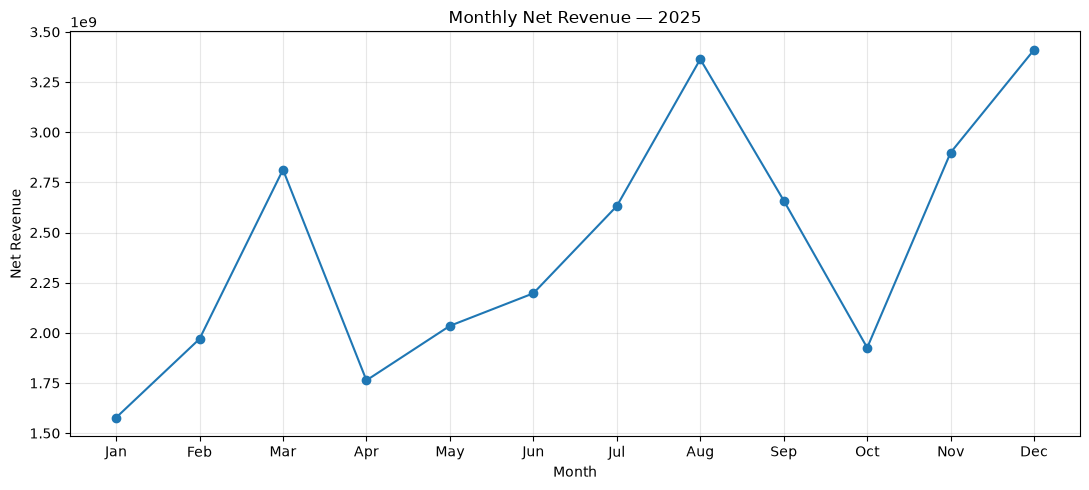

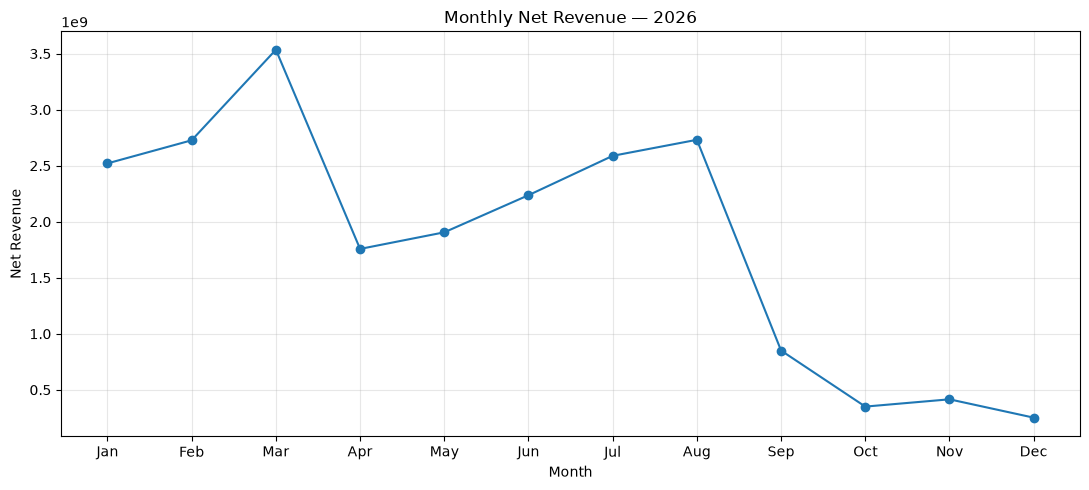

In [91]:
for year in [2025, 2026]:
    plot_data = monthly_analysis[
        monthly_analysis['year'] == year
    ].sort_values('month')

    plt.figure(figsize=(11, 5))
    plt.plot(
        plot_data['month_label'],
        plot_data['net_revenue'],
        marker='o'
    )

    plt.title(f'Monthly Net Revenue — {year}')
    plt.xlabel('Month')
    plt.ylabel('Net Revenue')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

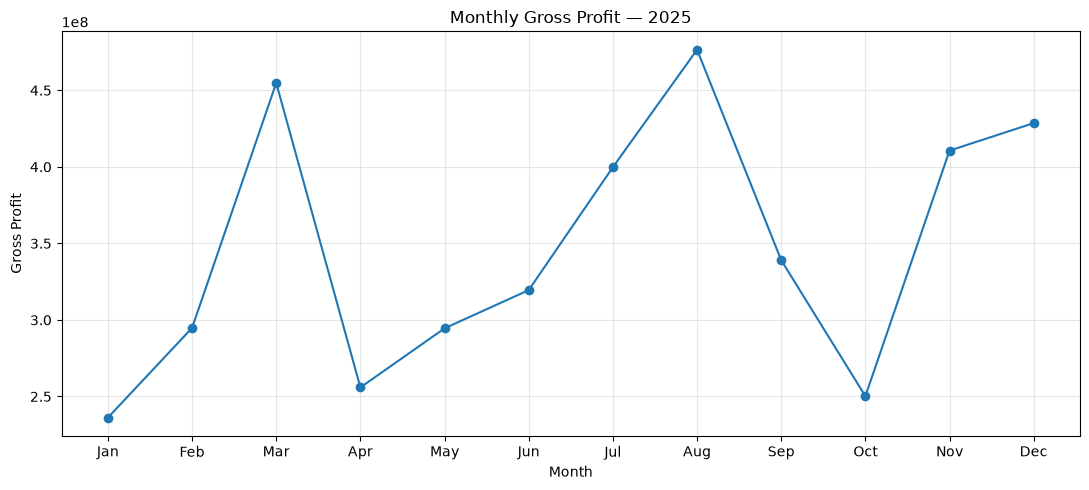

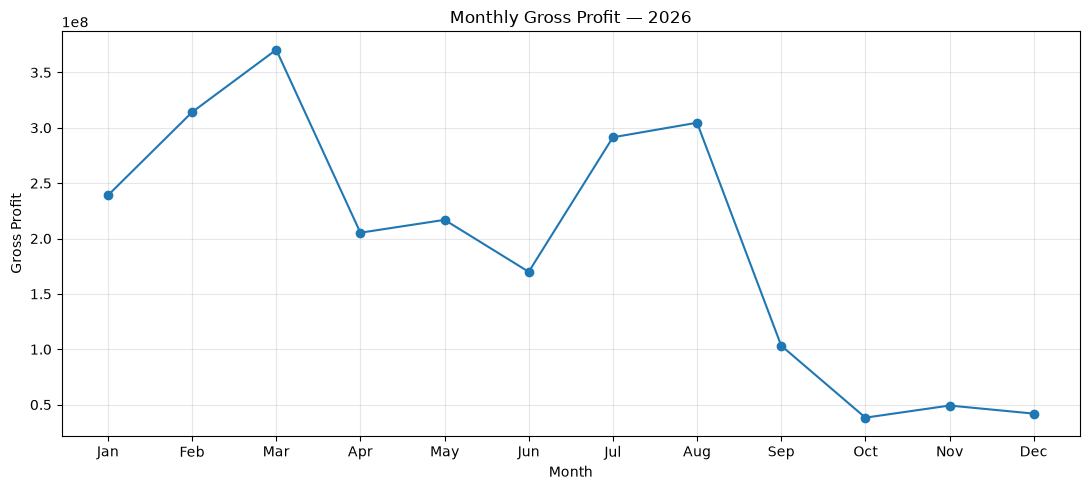

In [92]:
for year in [2025, 2026]:
    plot_data = monthly_analysis[
        monthly_analysis['year'] == year
    ].sort_values('month')

    plt.figure(figsize=(11, 5))
    plt.plot(
        plot_data['month_label'],
        plot_data['gross_profit'],
        marker='o'
    )

    plt.title(f'Monthly Gross Profit — {year}')
    plt.xlabel('Month')
    plt.ylabel('Gross Profit')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Kinerja perusahaan menunjukkan dua kondisi yang berbeda. Dari sisi pendapatan, net revenue FY2026 YTD meningkat sekitar 8,99% dibandingkan FY2025. Namun, gross profit turun sebesar 22,71% dan gross margin menurun dari 14,89% menjadi 10,56%.

Tren bulanan juga memperlihatkan penurunan revenue dan gross profit yang tajam sejak September 2026. Hal ini menjadi sinyal penting bagi perusahaan untuk mengevaluasi kinerja penjualan dan profitabilitas pada periode tersebut.

Temuan utama: Peningkatan revenue belum menghasilkan peningkatan keuntungan kotor. Perusahaan perlu menelusuri perubahan biaya, kebijakan diskon, dan komposisi produk untuk memahami penyebab penurunan profitabilitas.

## TASK 2 — Diagnostic Analysis: Why Did Revenue Grow While Gross Profit Fell?

In [93]:
comparison = df[
    (df['year'].isin([2025, 2026])) &
    (df['month'].between(1, 8))
].copy()

comparison['eligible_cost'] = comparison['cost'].where(
    comparison['status'].isin(['Completed', 'Returned']),
    0
)

comparison_summary = (
    comparison.groupby('year')
    .agg(
        net_revenue=('net_revenue', 'sum'),
        cost_total=('eligible_cost', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        cost_imputed_rows=('cost_imputed', 'sum'),
        missing_cost=('cost', lambda x: x.isna().sum())
    )
)

comparison_summary['gross_margin_pct'] = (
    comparison_summary['gross_profit']
    / comparison_summary['net_revenue']
    * 100
)

display(comparison_summary)

,net_revenue,cost_total,gross_profit,cost_imputed_rows,missing_cost,gross_margin_pct
year,,,,,,
2025,1.835128e+10,1.568495e+10,2.732011e+09,144,8,14.887306
2026,2.000149e+10,1.789412e+10,2.111689e+09,164,8,10.557656


In [94]:
# Analisis berdasarkan kategori produk
category_analysis = (
    comparison.groupby(['year', 'category'], as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        cost_imputed_rows=('cost_imputed', 'sum'),
        missing_cost=('cost', lambda x: x.isna().sum())
    )
)

category_analysis['gross_margin_pct'] = (
    category_analysis['gross_profit']
    / category_analysis['net_revenue'].replace(0, np.nan)
    * 100
)

category_pivot = category_analysis.pivot(
    index='category',
    columns='year',
    values=['net_revenue', 'gross_profit', 'gross_margin_pct']
)

display(category_analysis.sort_values(['category', 'year']))
display(category_pivot)

,year,category,net_revenue,gross_profit,cost_imputed_rows,missing_cost,gross_margin_pct
0,2025,Aksesoris,1.514517e+09,541739100.0,5,0,35.769758
7,2026,Aksesoris,1.484070e+09,506452324.8,7,0,34.125894
1,2025,Laptop,7.680780e+09,534680800.0,3,0,6.961283
8,2026,Laptop,9.508355e+09,358711172.6,3,0,3.772589
2,2025,Networking,1.538667e+09,422688150.0,131,8,27.471061
9,2026,Networking,1.292490e+09,335676550.0,147,7,25.971307
3,2025,Peralatan Kantor,2.485173e+09,683439100.0,3,0,27.500669
10,2026,Peralatan Kantor,2.308529e+09,606047854.8,3,0,26.252551
4,2025,Printer & Tinta,1.240071e+09,209813000.0,1,0,16.919434
11,2026,Printer & Tinta,1.072449e+09,156620400.0,2,0,14.603995


net_revenue               gross_profit               \
year                      2025          2026         2025         2026   
category                                                                 
Aksesoris         1.514517e+09  1.484070e+09  541739100.0  506452324.8   
Laptop            7.680780e+09  9.508355e+09  534680800.0  358711172.6   
Networking        1.538667e+09  1.292490e+09  422688150.0  335676550.0   
Peralatan Kantor  2.485173e+09  2.308529e+09  683439100.0  606047854.8   
Printer & Tinta   1.240071e+09  1.072449e+09  209813000.0  156620400.0   
Smartphone        3.877650e+09  4.310710e+09  334571400.0  138979946.5   
aksesoris         1.441800e+07  2.488900e+07    5079100.0    9200500.0   

                 gross_margin_pct             
year                         2025       2026  
category                                      
Aksesoris               35.769758  34.125894  
Laptop                   6.961283   3.772589  
Networking              27.471061  25.971307  
Peralatan Kantor        27.500669  26.252551  
Printer & Tinta         16.919434  14.603995  
Smartphone               8.628200   3.224062  
aksesoris               35.227493  36.966130

In [95]:
# Analisis berdasarkan produk
product_analysis = (
    comparison.groupby(['year', 'product'], as_index=False)
    .agg(
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        units_sold=('qty', 'sum'),
        missing_cost=('cost', lambda x: x.isna().sum()),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

product_analysis['gross_margin_pct'] = (
    product_analysis['gross_profit']
    / product_analysis['net_revenue'].replace(0, np.nan)
    * 100
)

product_profit_pivot = product_analysis.pivot(
    index='product',
    columns='year',
    values='gross_profit'
)

product_profit_pivot['profit_change'] = (
    product_profit_pivot[2026]
    - product_profit_pivot[2025]
)

display(
    product_profit_pivot
    .sort_values('profit_change')
)

year,2025,2026,profit_change
product,,,
Laptop Axio Pro 15,257122600.0,108289750.0,-148832850.0
Smartphone Lumo X,210327800.0,95334924.1,-114992875.9
Router WiFi 6 R600,291493150.0,187090350.0,-104402800.0
Kursi Ergonomis E1,665639000.0,584508200.0,-81130800.0
Smartphone Lumo A5,124243600.0,43645022.4,-80598577.6
Printer InkJet P200,162092000.0,94591000.0,-67501000.0
Laptop Axio 14,170884800.0,116754324.8,-54130475.2
Headset USB H3,156045500.0,102814800.0,-53230700.0
Mouse Wireless M20,54448300.0,49567104.8,-4881195.2


In [96]:
# Apakah diskon berkontribusi terhadapa penurunan margin
discount_analysis = (
    comparison[
        comparison['status'] == 'Completed'
    ]
    .groupby('year', as_index=False)
    .agg(
        avg_discount=('discount', 'mean'),
        median_discount=('discount', 'median'),
        net_revenue=('net_revenue', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        imputed_cost_rows=('cost_imputed', 'sum')
    )
)

discount_analysis['gross_margin_pct'] = (
    discount_analysis['gross_profit']
    / discount_analysis['net_revenue'].replace(0, np.nan)
    * 100
)

display(discount_analysis)

,year,avg_discount,median_discount,net_revenue,gross_profit,imputed_cost_rows,gross_margin_pct
0,2025,0.039405,0.05,1.864970e+10,2.778290e+09,144,14.897237
1,2026,0.073308,0.05,2.032828e+10,2.228356e+09,164,10.961853


Analisis menunjukkan bahwa net revenue meningkat sekitar 9% pada 2026, tetapi gross profit menurun dan gross margin melemah dari 14,90% menjadi 10,96%. Pada periode yang sama, rata-rata diskon meningkat dari 3,94% menjadi 7,33%. Perubahan ini mengindikasikan adanya tekanan terhadap profitabilitas, dengan peningkatan diskon sebagai salah satu faktor yang perlu ditelusuri lebih lanjut.

Pada tingkat produk, penurunan gross profit terbesar ditemukan pada Laptop Axio Pro 15, Smartphone Lumo X, dan Router WiFi 6 R600. Sebaliknya, beberapa produk, seperti Keyboard Mekanik K7 dan Laptop Veno 13, mencatat peningkatan laba kotor. Hal ini menunjukkan bahwa perubahan profitabilitas berbeda antarproduk dan membutuhkan pendekatan evaluasi yang lebih terarah.

Perusahaan disarankan untuk mengevaluasi strategi diskon dan harga jual pada produk yang mengalami penurunan profit, memeriksa perubahan biaya produk, serta mengidentifikasi faktor keberhasilan produk yang profitabilitasnya meningkat. Validasi biaya hasil imputasi juga diperlukan agar keputusan bisnis didasarkan pada estimasi laba yang lebih andal.

# Task 3

In [97]:
# Persiapkan data revenue bulanan
# Ambil transaksi yang selesai
completed = df[df['status'] == 'Completed'].copy()

# Agregasi revenue per bulan
monthly_revenue = (
    completed
    .groupby(
        completed['order_date'].dt.to_period('M')
    )['revenue']
    .sum()
    .rename_axis('period')
    .reset_index(name='revenue')
)

monthly_revenue['month_date'] = (
    monthly_revenue['period'].dt.to_timestamp()
)

monthly_revenue = monthly_revenue.sort_values('month_date')

display(monthly_revenue)

,period,revenue,month_date
0,2024-09,1.872006e+09,2024-09-01
1,2024-10,3.488787e+09,2024-10-01
2,2024-11,2.283058e+09,2024-11-01
3,2024-12,2.621518e+09,2024-12-01
4,2025-01,1.605885e+09,2025-01-01
5,2025-02,2.003531e+09,2025-02-01
6,2025-03,2.846235e+09,2025-03-01
7,2025-04,1.776243e+09,2025-04-01
8,2025-05,2.066078e+09,2025-05-01
9,2025-06,2.240673e+09,2025-06-01


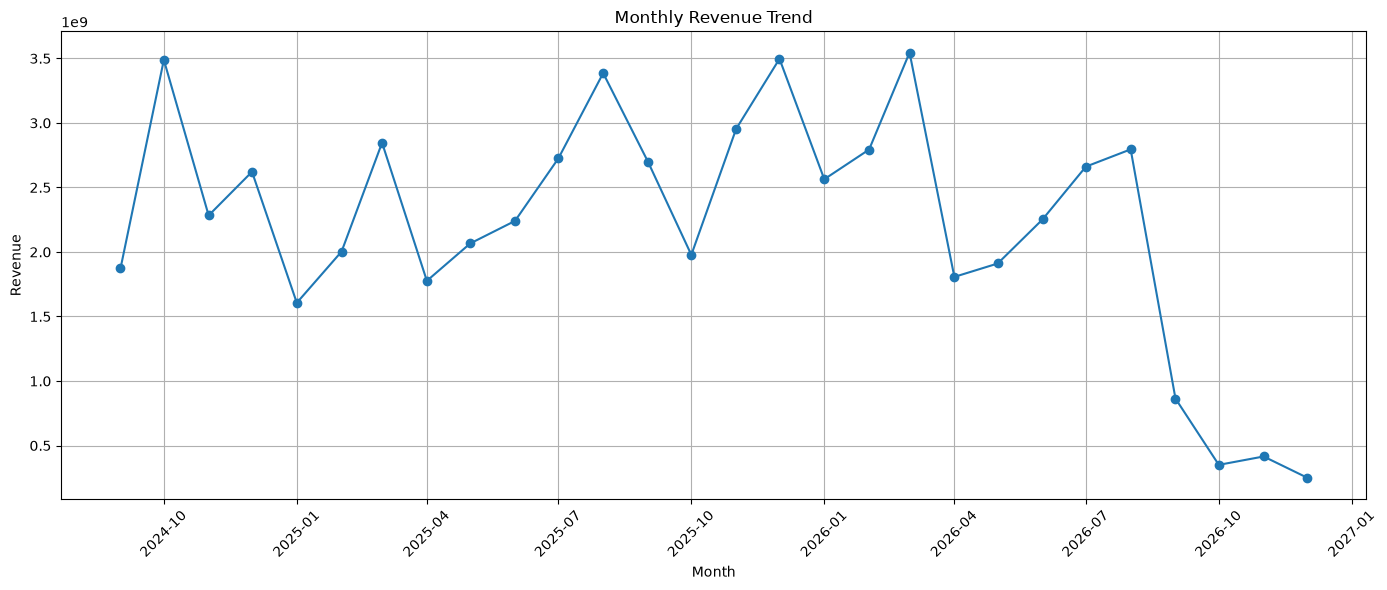

In [98]:
# Visualisasi tren revenue bulanan
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue['month_date'],
    monthly_revenue['revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [99]:
# Ambil 3 bulan terakhir yang datanya tersedia
last_3_months = monthly_revenue.tail(3)

baseline_revenue = last_3_months['revenue'].mean()

print("Revenue 3 bulan terakhir:")
display(last_3_months)

print(
    f"Baseline forecast per bulan: "
    f"Rp{baseline_revenue:,.0f}"
)

Revenue 3 bulan terakhir:


,period,revenue,month_date
25,2026-10,350262250.0,2026-10-01
26,2026-11,415186000.0,2026-11-01
27,2026-12,251582500.0,2026-12-01


Baseline forecast per bulan: Rp339,010,250


In [100]:
forecast_months = pd.date_range(
    start='2027-01-01',
    periods=3,
    freq='MS'
)

baseline_forecast = pd.DataFrame({
    'month_date': forecast_months,
    'forecast_revenue': [baseline_revenue] * 3
})

baseline_forecast['month'] = (
    baseline_forecast['month_date'].dt.strftime('%B %Y')
)

display(baseline_forecast)

,month_date,forecast_revenue,month
0,2027-01-01,339010250.0,January 2027
1,2027-02-01,339010250.0,February 2027
2,2027-03-01,339010250.0,March 2027


In [101]:
# Agregasi revenue Completed berdasarkan tahun dan bulan
monthly_revenue['year'] = monthly_revenue['month_date'].dt.year
monthly_revenue['month'] = monthly_revenue['month_date'].dt.month

# Revenue Januari-November untuk masing-masing tahun
jan_nov = monthly_revenue[
    monthly_revenue['month'].between(1, 11)
    & monthly_revenue['year'].isin([2025, 2026])
]

jan_nov_summary = (
    jan_nov.groupby('year')['revenue']
    .sum()
)

revenue_2025 = jan_nov_summary.get(2025, np.nan)
revenue_2026 = jan_nov_summary.get(2026, np.nan)

growth_factor = revenue_2026 / revenue_2025

print(f"Revenue Jan-Nov 2025: Rp{revenue_2025:,.0f}")
print(f"Revenue Jan-Nov 2026: Rp{revenue_2026:,.0f}")
print(f"Growth factor: {growth_factor:.4f}")
print(f"Growth rate: {(growth_factor - 1) * 100:.2f}%")

Revenue Jan-Nov 2025: Rp26,279,726,200
Revenue Jan-Nov 2026: Rp21,957,811,350
Growth factor: 0.8355
Growth rate: -16.45%


In [102]:
# Baseline Januari-Maret 2026
baseline_q1_2026 = monthly_revenue[
    (monthly_revenue['year'] == 2026)
    & (monthly_revenue['month'].between(1, 3))
].copy()

# Periksa apakah tersedia 3 bulan
if len(baseline_q1_2026) != 3:
    raise ValueError(
        "Data revenue Januari-Maret 2026 tidak lengkap."
    )

# Forecast Januari-Maret 2027
seasonal_forecast = baseline_q1_2026[
    ['month', 'revenue']
].copy()

seasonal_forecast['forecast_revenue'] = (
    seasonal_forecast['revenue'] * growth_factor
)

seasonal_forecast['forecast_month'] = (
    pd.to_datetime({
        'year': [2027] * len(seasonal_forecast),
        'month': seasonal_forecast['month'],
        'day': [1] * len(seasonal_forecast)
    })
)

seasonal_forecast = seasonal_forecast.rename(
    columns={'revenue': 'baseline_revenue_2026'}
)

seasonal_forecast = seasonal_forecast[
    [
        'forecast_month',
        'baseline_revenue_2026',
        'forecast_revenue'
    ]
]

display(seasonal_forecast)

,forecast_month,baseline_revenue_2026,forecast_revenue
16,2027-01-01,2.563635e+09,2.142025e+09
17,2027-02-01,2.793696e+09,2.334250e+09
18,2027-03-01,3.545110e+09,2.962087e+09


## Kesimpulan Task 3: Predictive Analysis

Berdasarkan analisis tren pendapatan bulanan, revenue perusahaan menunjukkan fluktuasi yang cukup tinggi sepanjang periode September 2024 hingga Desember 2026. Pendapatan bulanan sempat mencapai lebih dari Rp3 miliar, tetapi mengalami penurunan tajam pada akhir 2026. Revenue tercatat sebesar **Rp350,26 juta pada Oktober, Rp415,19 juta pada November, dan Rp251,58 juta pada Desember 2026**.

Berdasarkan metode baseline, estimasi revenue untuk Januari–Maret 2027 adalah **Rp339,01 juta per bulan**, sehingga total proyeksi selama tiga bulan mencapai sekitar **Rp1,02 miliar**.

Sementara itu, metode seasonal forecast menggunakan pola revenue Januari–Maret 2026 sebagai acuan dan menyesuaikannya dengan pertumbuhan revenue Januari–November. Hasilnya, faktor pertumbuhan sebesar **0,8355 atau penurunan 16,45%** menghasilkan proyeksi berikut:

| Bulan         |    Forecast Revenue |
| ------------- | ------------------: |
| Januari 2027  |     Rp2.142.025.000 |
| Februari 2027 |     Rp2.334.250.000 |
| Maret 2027    |     Rp2.962.087.000 |
| **Total**     | **Rp7.438.362.000** |

### Interpretasi dan Asumsi

Terdapat perbedaan yang cukup besar antara kedua metode. Baseline forecast menghasilkan estimasi yang lebih konservatif karena menggunakan rata-rata tiga bulan terakhir, sedangkan seasonal forecast mempertimbangkan pola pendapatan pada periode yang sama tahun sebelumnya dan penurunan revenue tahunan.

Namun, terdapat dua hal yang perlu diperhatikan:

1. **Data Desember 2026 belum mencakup satu bulan penuh.** Karena data terakhir hanya tersedia sampai 9 Desember 2026, revenue Desember yang sebesar Rp251,58 juta belum dapat dibandingkan secara langsung dengan bulan-bulan penuh. Hal ini juga dapat menurunkan hasil baseline forecast.
2. **Seasonal forecast mengasumsikan pola musiman berulang.** Proyeksi ini mengasumsikan pola revenue Januari–Maret 2026 masih relevan untuk 2027 dan penurunan revenue sebesar 16,45% dapat digunakan sebagai faktor penyesuaian. Asumsi ini perlu dievaluasi lebih lanjut karena perubahan harga, diskon, permintaan, dan strategi penjualan dapat memengaruhi hasil aktual.

### Rekomendasi

Untuk perencanaan bisnis, seasonal forecast dapat digunakan sebagai **skenario proyeksi awal**, dengan estimasi total revenue sekitar Rp7,44 miliar selama Januari–Maret 2027. Namun, angka ini sebaiknya tidak dianggap sebagai prediksi pasti. Perusahaan perlu mengevaluasi penyebab penurunan revenue, memeriksa kelengkapan data Desember, serta membandingkan hasil kedua metode menggunakan data historis sebelum menetapkan target penjualan.


# Task 4 - Prescriptive Analysis: What should we do?

Berdasarkan hasil descriptive, diagnostic, dan predictive analysis, perusahaan menghadapi tantangan berupa **revenue yang meningkat, tetapi gross profit dan gross margin menurun**. Selain itu, rata-rata diskon meningkat dari 3,94% pada 2025 menjadi 7,33% pada 2026, sedangkan proyeksi revenue Januari–Maret 2027 menunjukkan potensi penurunan dibandingkan periode yang sama tahun sebelumnya.

Oleh karena itu, berikut tiga rekomendasi strategis yang dapat dipertimbangkan oleh manajemen.

## 1. Evaluate Discount Policies and Product Profitability

**Masalah:** Rata-rata diskon meningkat dari 3,94% menjadi 7,33%, sementara gross margin turun dari 14,90% menjadi 10,96%. Hal ini mengindikasikan adanya tekanan terhadap profitabilitas yang perlu ditelusuri lebih lanjut.

**Rekomendasi:**

* Evaluasi pemberian diskon berdasarkan produk, kategori, dan channel penjualan.
* Tetapkan batas diskon berdasarkan margin minimum yang ditargetkan perusahaan.
* Prioritaskan promosi pada produk yang memiliki margin sehat dan kontribusi profit yang baik.
* Evaluasi produk dengan penurunan gross profit terbesar, seperti Laptop Axio Pro 15 dan Smartphone Lumo X.

**Expected impact:** Membantu mengendalikan pengurangan margin akibat diskon berlebihan dan meningkatkan profitabilitas penjualan.

**KPI untuk evaluasi:**

* Gross margin (%).
* Average discount (%).
* Gross profit per product.
* Revenue dan profit dari transaksi promosi.

## 2. Optimize Product Portfolio and Sales Strategy

**Masalah:** Tidak semua produk menunjukkan kinerja yang sama. Beberapa produk mengalami penurunan gross profit, sedangkan produk lain, seperti Laptop Veno 13 dan Keyboard Mekanik K7, menunjukkan peningkatan gross profit.

**Rekomendasi:**

* Identifikasi produk dengan pertumbuhan revenue dan gross profit yang positif.
* Evaluasi harga jual, biaya pengadaan, dan strategi promosi pada produk dengan penurunan profit.
* Tingkatkan upaya pemasaran untuk produk yang memiliki margin sehat dan permintaan yang baik.
* Analisis kinerja berdasarkan kategori, wilayah, dan channel untuk menemukan peluang pertumbuhan yang lebih menguntungkan.

**Expected impact:** Membantu perusahaan mengalokasikan anggaran pemasaran dan sumber daya penjualan kepada produk serta segmen yang memberikan kontribusi profit lebih baik.

**KPI untuk evaluasi:**

* Gross profit per product/category.
* Gross margin per category.
* Revenue growth per region/channel.
* Kontribusi profit dari produk prioritas.

## 3. Improve Revenue Forecasting and Monthly Performance Monitoring

**Masalah:** Revenue bulanan mengalami fluktuasi yang cukup besar. Forecast awal untuk Januari–Maret 2027 juga menunjukkan hasil yang berbeda berdasarkan metode yang digunakan.

**Rekomendasi:**

* Buat dashboard pemantauan revenue, gross profit, gross margin, dan diskon secara bulanan.
* Bandingkan realisasi penjualan dengan target dan forecast.
* Gunakan data historis dengan periode yang sebanding untuk memperbarui proyeksi penjualan.
* Tetapkan tindakan korektif ketika revenue atau gross margin berada di bawah target, misalnya mengevaluasi promosi, ketersediaan produk, dan strategi penjualan.

**Expected impact:** Membantu manajemen mendeteksi penurunan kinerja lebih awal, memperbaiki perencanaan penjualan, dan mengambil keputusan berdasarkan data.

**KPI untuk evaluasi:**

* Revenue aktual vs. forecast.
* Forecast error (MAE atau MAPE).
* Monthly gross profit.
* Gross margin (%).

---

## Prioritas Implementasi

| Prioritas | Rekomendasi                                       | Jangka Waktu           | Indikator Keberhasilan                                   |
| --------- | ------------------------------------------------- | ---------------------- | -------------------------------------------------------- |
| 1         | Evaluasi diskon dan profitabilitas produk         | Jangka pendek          | Gross margin membaik dan diskon lebih terkendali         |
| 2         | Optimasi portofolio produk dan strategi penjualan | Jangka menengah        | Kontribusi gross profit produk prioritas meningkat       |
| 3         | Implementasi dashboard dan evaluasi forecast      | Jangka pendek–menengah | Penurunan forecast error dan deteksi masalah lebih cepat |

### Kesimpulan

Perusahaan sebaiknya tidak hanya berfokus pada peningkatan revenue, tetapi juga memastikan bahwa pertumbuhan penjualan menghasilkan profit yang sehat. Prioritas utama adalah mengevaluasi kebijakan diskon dan profitabilitas produk, mengoptimalkan strategi penjualan berdasarkan kontribusi profit, serta memperkuat pemantauan kinerja melalui dashboard dan forecasting.

**Keberhasilan strategi perlu diukur dari peningkatan gross profit dan gross margin, bukan hanya dari pertumbuhan revenue.** Target numerik sebaiknya ditetapkan setelah manajemen mengevaluasi kondisi aktual, kualitas data biaya, dan kelayakan setiap rekomendasi.


# Task 5 — Executive Summary

## Executive Summary: Sales Performance and Profitability Analysis (2025–2026)

### 1. Business Overview

Analisis data penjualan selama 2025 dan 2026 menunjukkan bahwa perusahaan menghadapi tantangan dalam mempertahankan profitabilitas di tengah perubahan kinerja penjualan. Berdasarkan data tahunan yang tersedia, net revenue meningkat dari **Rp18,35 miliar pada 2025 menjadi Rp20,00 miliar pada 2026 YTD**, atau naik sekitar 8,99%.

Namun, peningkatan revenue tersebut tidak diikuti oleh peningkatan keuntungan. Gross profit justru turun dari Rp2,73 miliar menjadi Rp2,11 miliar, atau berkurang sekitar 22,71%. Gross margin juga turun dari 14,89% menjadi 10,56%, yang menunjukkan bahwa perusahaan memperoleh keuntungan kotor lebih kecil dari setiap rupiah pendapatan.

Perlu diperhatikan bahwa data 2026 belum mencakup satu tahun penuh, sehingga perbandingan tahunan perlu dikonfirmasi menggunakan periode yang setara.

### 2. Key Findings

**A. Revenue meningkat, tetapi profitabilitas menurun**

Net revenue meningkat sekitar Rp1,65 miliar, tetapi gross profit berkurang sekitar Rp620,32 juta. Kondisi ini menunjukkan bahwa pertumbuhan pendapatan belum menghasilkan peningkatan keuntungan kotor.

**B. Penurunan kinerja bulanan sejak September 2026**

Data menunjukkan penurunan tajam pada revenue dan gross profit mulai September 2026. Revenue turun dari sekitar Rp2,73 miliar pada Agustus menjadi Rp850,27 juta pada September, kemudian mencapai Rp350,26 juta pada Oktober dan Rp415,19 juta pada November. Revenue Desember tercatat Rp251,58 juta, tetapi data bulan tersebut belum lengkap.

Pola ini perlu segera ditelusuri untuk menentukan apakah penurunan disebabkan oleh perubahan permintaan, aktivitas penjualan, ketersediaan produk, atau faktor pencatatan data.

**C. Penurunan gross margin menjadi perhatian utama**

Gross margin turun dari 14,89% pada 2025 menjadi 10,56% pada 2026 YTD. Selain itu, rata-rata diskon meningkat dari 3,94% menjadi 7,33% berdasarkan ringkasan analisis sebelumnya.

Peningkatan diskon merupakan salah satu faktor yang perlu dievaluasi, tetapi belum dapat disimpulkan sebagai penyebab langsung penurunan gross margin tanpa analisis lebih lanjut terhadap harga jual dan biaya produk.

**D. Performa produk tidak merata**

Analisis produk menunjukkan bahwa beberapa produk mengalami penurunan gross profit yang signifikan. Di antaranya Laptop Axio Pro 15, Smartphone Lumo X, dan Router WiFi 6 R600.

Sebaliknya, beberapa produk seperti Laptop Veno 13 dan Keyboard Mekanik K7 menunjukkan peningkatan gross profit. Perbedaan ini memberikan peluang bagi perusahaan untuk mengevaluasi kembali strategi harga, promosi, dan alokasi sumber daya penjualan berdasarkan kontribusi profit setiap produk.

**E. Kualitas data biaya perlu diperhatikan**

Sebagian nilai biaya diperoleh melalui imputasi karena data biaya asli tidak tersedia, dan beberapa transaksi masih memiliki biaya kosong. Kondisi ini dapat memengaruhi akurasi perhitungan gross profit dan gross margin. Oleh karena itu, hasil analisis profitabilitas perlu divalidasi sebelum dijadikan dasar keputusan keuangan.

### 3. Revenue Forecast for January–March 2027

Forecasting dilakukan menggunakan dua pendekatan untuk memberikan gambaran awal mengenai kemungkinan kinerja penjualan pada kuartal pertama 2027.

| Forecast Method   |  January 2027 | February 2027 |    March 2027 | Total Q1 2027 |
| ----------------- | ------------: | ------------: | ------------: | ------------: |
| Baseline Forecast | Rp339,01 juta | Rp339,01 juta | Rp339,01 juta | Rp1,02 miliar |
| Seasonal Forecast | Rp2,14 miliar | Rp2,33 miliar | Rp2,96 miliar | Rp7,44 miliar |

Baseline forecast menggunakan rata-rata revenue tiga bulan terakhir yang tersedia. Seasonal forecast menggunakan revenue Januari–Maret 2026 yang disesuaikan dengan faktor pertumbuhan Januari–November, yaitu sekitar 0,8355 atau penurunan 16,45%.

Perbedaan hasil kedua metode cukup besar. Selain itu, baseline dipengaruhi oleh rendahnya revenue pada akhir 2026, sementara seasonal forecast mengasumsikan pola pendapatan awal tahun sebelumnya masih relevan.

Dengan demikian, kedua hasil tersebut sebaiknya diperlakukan sebagai **skenario awal, bukan target penjualan atau prediksi yang pasti**. Perusahaan perlu memvalidasi kelengkapan data Desember dan menguji akurasi model menggunakan data historis sebelum memilih forecast yang paling sesuai.

### 4. Strategic Recommendations

Berdasarkan keseluruhan temuan, terdapat tiga rekomendasi utama bagi manajemen.

**1. Evaluate discount policies and product profitability**

Evaluasi pemberian diskon berdasarkan kategori dan produk. Tetapkan batas diskon berdasarkan margin minimum yang ditargetkan, serta prioritaskan promosi pada produk yang memiliki kontribusi profit yang sehat.

Target evaluasi:

* Meningkatkan gross margin.
* Mengendalikan rata-rata diskon.
* Meningkatkan gross profit per produk.

**2. Optimize product portfolio and sales strategy**

Identifikasi produk yang memiliki kontribusi profit positif dan peluang pertumbuhan. Evaluasi produk dengan penurunan gross profit terbesar, termasuk harga jual, biaya pengadaan, serta efektivitas promosi.

Target evaluasi:

* Meningkatkan kontribusi gross profit produk prioritas.
* Mengalokasikan anggaran pemasaran secara lebih efektif.
* Memperbaiki kinerja kategori dan channel penjualan.

**3. Strengthen data monitoring and forecasting**

Bangun dashboard untuk memantau revenue, gross profit, gross margin, diskon, dan performa produk secara berkala. Lakukan perbandingan antara realisasi dan forecast agar penurunan kinerja dapat dideteksi lebih awal.

Target evaluasi:

* Mengurangi forecast error.
* Mempercepat identifikasi penurunan penjualan.
* Meningkatkan kualitas pengambilan keputusan berbasis data.

Selain itu, perusahaan perlu meningkatkan kelengkapan pencatatan biaya agar analisis profitabilitas menjadi lebih akurat.

### 5. Conclusion for Management

Secara keseluruhan, perusahaan menunjukkan pertumbuhan revenue, tetapi menghadapi penurunan gross profit dan gross margin. Penurunan kinerja bulanan sejak September 2026 serta penurunan profit pada sejumlah produk menjadi sinyal bahwa perusahaan perlu mengevaluasi strategi penjualan dan pengelolaan biaya.

Fokus perusahaan ke depan sebaiknya tidak hanya meningkatkan volume penjualan, tetapi juga memastikan bahwa setiap transaksi memberikan kontribusi keuntungan yang memadai. Evaluasi kebijakan diskon, optimalisasi portofolio produk, dan penguatan pemantauan kinerja perlu menjadi prioritas.

Forecast revenue untuk kuartal pertama 2027 dapat digunakan sebagai referensi perencanaan awal, tetapi harus divalidasi lebih lanjut karena kedua metode menghasilkan estimasi yang berbeda secara signifikan.

**Pesan utama untuk manajemen: Pertumbuhan revenue tidak selalu berarti peningkatan kinerja bisnis. Prioritas perusahaan adalah memulihkan profitabilitas, memahami penurunan kinerja sejak September 2026, dan memperkuat kualitas data agar keputusan bisnis lebih akurat dan terukur.**


# Create .xlsx file

In [103]:
# Export dataframe ke xlsx
output_file = 'forecast_revenue.xlsx'
df.to_excel(output_file, index=False)